In [ ]:
"pip install tensorflow opencv-python numpy pandas matplotlib seaborn scikit-learn pillow"

In [3]:

import os
from pathlib import Path
import pandas as pd

# Dataset location
DATASET_PATH = Path(
    r"C:\Users\Chaithanya Reddy\Projects\Brain_Tumor_AI_Project\brain_tumor"
)

TRAIN_PATH = DATASET_PATH / "classification_task" / "train"
TEST_PATH = DATASET_PATH / "classification_task" / "test"

classes = ["glioma", "meningioma", "pituitary", "no_tumor"]

print("Dataset exists:", DATASET_PATH.exists())

print("\nTRAINING DATA")

for category in classes:
    folder = TRAIN_PATH / category
    images = list(folder.glob("*.jpg"))
    print(category, ":", len(images))

print("\nTESTING DATA")

for category in classes:
    folder = TEST_PATH / category
    images = list(folder.glob("*.jpg"))
    print(category, ":", len(images))


Dataset exists: True

TRAINING DATA
glioma : 1147
meningioma : 1329
pituitary : 1457
no_tumor : 1067

TESTING DATA
glioma : 254
meningioma : 306
pituitary : 300
no_tumor : 140


In [4]:
from pathlib import Path

DATASET_PATH = Path(
    r"C:\Users\Chaithanya Reddy\Projects\Brain_Tumor_AI_Project\brain_tumor"
)

TRAIN_PATH = DATASET_PATH / "classification_task" / "train"
TEST_PATH = DATASET_PATH / "classification_task" / "test"

CLASSES = ["glioma", "meningioma", "pituitary", "no_tumor"]

print("Dataset:", DATASET_PATH)
print("Training folder exists:", TRAIN_PATH.exists())
print("Testing folder exists:", TEST_PATH.exists())

Dataset: C:\Users\Chaithanya Reddy\Projects\Brain_Tumor_AI_Project\brain_tumor
Training folder exists: True
Testing folder exists: True


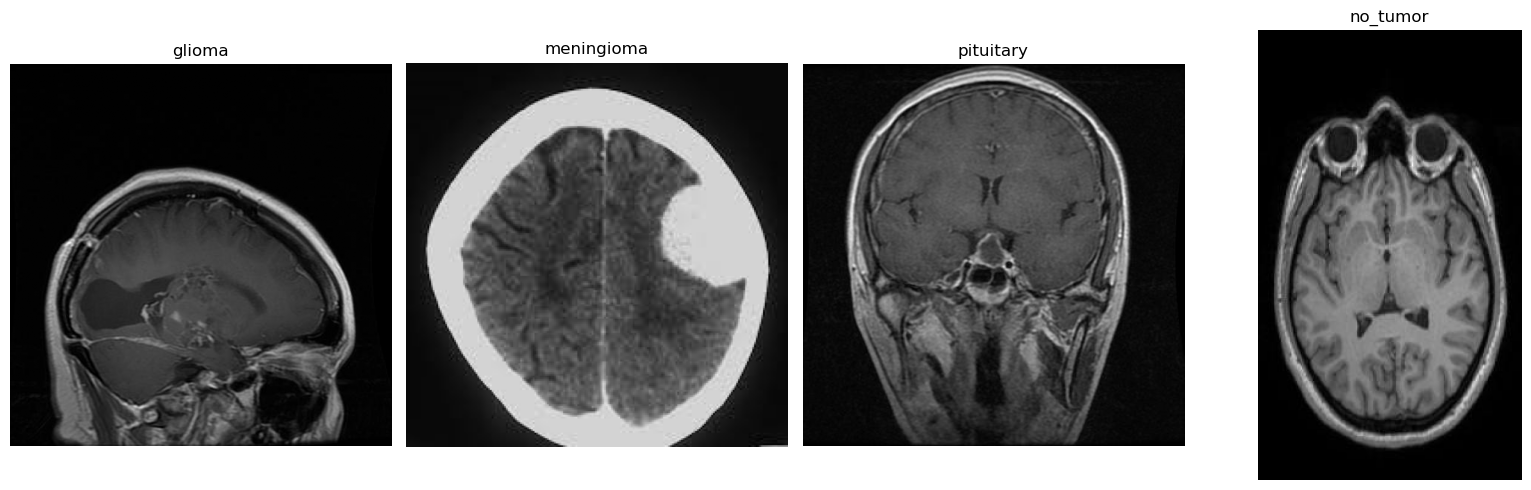

In [5]:
import matplotlib.pyplot as plt
from PIL import Image
import random

fig, axes = plt.subplots(1, 4, figsize=(16, 5))

for i, class_name in enumerate(CLASSES):

    image_files = list((TRAIN_PATH / class_name).glob("*"))

    image_path = random.choice(image_files)

    image = Image.open(image_path)

    axes[i].imshow(image, cmap="gray")
    axes[i].set_title(class_name)
    axes[i].axis("off")

plt.tight_layout()
plt.show()

In [6]:
from collections import Counter

dimensions = Counter()
formats = Counter()

for class_name in CLASSES:

    image_files = list((TRAIN_PATH / class_name).glob("*"))

    for image_path in image_files:

        try:
            with Image.open(image_path) as img:
                dimensions[img.size] += 1
                formats[img.format] += 1

        except Exception as e:
            print("Problem with:", image_path, e)

print("Image dimensions:")
print(dimensions.most_common(10))

print("\nImage formats:")
print(formats)

Image dimensions:
[((512, 512), 4120), ((369, 369), 323), ((216, 369), 277), ((256, 256), 27), ((187, 369), 21), ((202, 369), 19), ((225, 225), 13), ((210, 369), 12), ((236, 236), 11), ((442, 442), 6)]

Image formats:
Counter({'JPEG': 5000})


In [7]:
from collections import Counter
from PIL import Image
import pandas as pd

dimension_data = []

for class_name in CLASSES:
    folder = TRAIN_PATH / class_name

    for image_path in folder.iterdir():
        if image_path.is_file():
            try:
                with Image.open(image_path) as img:
                    dimension_data.append({
                        "class": class_name,
                        "width": img.width,
                        "height": img.height,
                        "format": img.format
                    })
            except Exception:
                print("Unreadable image:", image_path)

df_dimensions = pd.DataFrame(dimension_data)

print("Total readable images:", len(df_dimensions))

print("\nMost common dimensions by class:")
for class_name in CLASSES:
    print(f"\n{class_name}")
    print(
        df_dimensions[df_dimensions["class"] == class_name]
        .groupby(["width", "height"])
        .size()
        .sort_values(ascending=False)
        .head(10)
    )

Total readable images: 5000

Most common dimensions by class:

glioma
width  height
512    512       1147
dtype: int64

meningioma
width  height
512    512       1201
225    225          8
455    500          3
442    442          3
554    554          2
485    510          2
212    237          2
341    395          2
213    237          2
201    251          2
dtype: int64

pituitary
width  height
512    512       1418
256    256         24
474    474          2
201    210          1
202    202          1
360    378          1
400    400          1
442    442          1
470    432          1
502    502          1
dtype: int64

no_tumor
width  height
512    512       354
369    369       323
216    369       277
187    369        21
202    369        19
210    369        12
236    236        11
225    225         5
442    442         2
733    781         2
dtype: int64


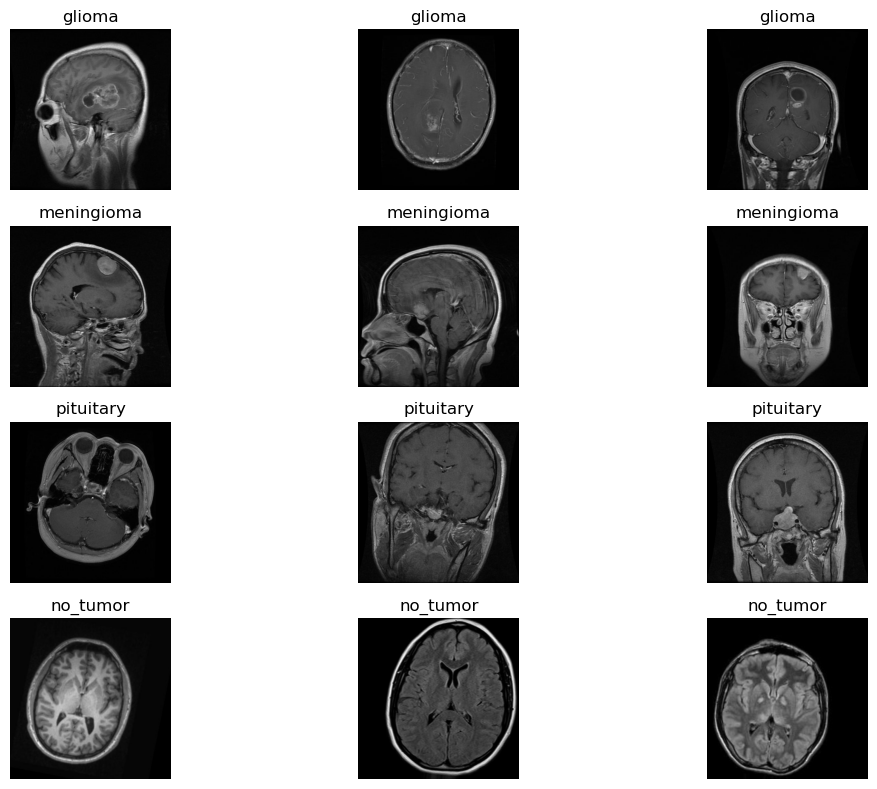

In [12]:
import matplotlib.pyplot as plt
import random
from PIL import Image

fig, axes = plt.subplots(4, 3, figsize=(12, 8))

for row, class_name in enumerate(CLASSES):

    image_files = [
        p for p in (TRAIN_PATH / class_name).iterdir()
        if p.is_file()
    ]

    samples = random.sample(image_files, min(3, len(image_files)))

    for col, image_path in enumerate(samples):
        with Image.open(image_path) as img:
            axes[row, col].imshow(img.convert("RGB"))

        axes[row, col].set_title(class_name)
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

In [13]:
from collections import Counter
import pandas as pd
from PIL import Image

def get_dimension_summary(folder, split_name):
    records = []

    for class_name in CLASSES:
        class_folder = folder / class_name

        for image_path in class_folder.iterdir():
            if image_path.is_file():
                try:
                    with Image.open(image_path) as img:
                        records.append({
                            "split": split_name,
                            "class": class_name,
                            "width": img.width,
                            "height": img.height
                        })
                except Exception:
                    print("Unreadable:", image_path)

    return pd.DataFrame(records)

train_dimensions = get_dimension_summary(TRAIN_PATH, "Train")
test_dimensions = get_dimension_summary(TEST_PATH, "Test")

all_dimensions = pd.concat(
    [train_dimensions, test_dimensions],
    ignore_index=True
)

summary = (
    all_dimensions
    .groupby(["split", "class", "width", "height"])
    .size()
    .reset_index(name="count")
    .sort_values(["split", "class", "count"], ascending=[True, True, False])
)

print(summary.to_string(index=False))

split      class  width  height  count
 Test     glioma    512     512    254
 Test meningioma    512     512    188
 Test meningioma    225     225      7
 Test meningioma    442     442      4
 Test meningioma    201     251      3
 Test meningioma    210     240      3
 Test meningioma    554     554      3
 Test meningioma    200     223      2
 Test meningioma    212     237      2
 Test meningioma    228     221      2
 Test meningioma    341     395      2
 Test meningioma    455     500      2
 Test meningioma    174     230      1
 Test meningioma    200     235      1
 Test meningioma    200     236      1
 Test meningioma    200     252      1
 Test meningioma    201     207      1
 Test meningioma    204     249      1
 Test meningioma    205     251      1
 Test meningioma    206     245      1
 Test meningioma    206     249      1
 Test meningioma    208     243      1
 Test meningioma    209     241      1
 Test meningioma    211     239      1
 Test meningioma    212  

In [14]:
README_PATH = DATASET_PATH / "README.md"
MANIFEST_PATH = DATASET_PATH / "manifest.csv"

print("README exists:", README_PATH.exists())
print("Manifest exists:", MANIFEST_PATH.exists())

if README_PATH.exists():
    print("\n--- DATASET README ---")
    print(README_PATH.read_text(encoding="utf-8")[:10000])

if MANIFEST_PATH.exists():
    print("\n--- MANIFEST ---")
    manifest = pd.read_csv(MANIFEST_PATH)
    print(manifest.head())
    print("\nColumns:")
    print(manifest.columns.tolist())

README exists: True
Manifest exists: True

--- DATASET README ---
# BRISC 2025 — Brain Tumor MRI Dataset

> **BRISC** (BRain tumor Image Segmentation & Classification) — a curated, expert-annotated T1 MRI dataset for multi-class brain tumor classification and pixel-wise segmentation.

[ArXiv preprint (Fateh et al., 2025)](https://arxiv.org/abs/2506.14318)

---

## 🚀 Overview

BRISC is designed to address common shortcomings in existing public brain MRI collections (e.g., class imbalance, limited tumor types, and annotation inconsistency). It provides high-quality, physician-validated pixel-level masks and a balanced multi-class classification split, suitable for benchmarking segmentation and classification algorithms as well as multi-task learning research.

**Highlights**
- 6,000 T1-weighted MRI slices (5,000 train / 1,000 test)
- Four classes: **Glioma**, **Meningioma**, **Pituitary Tumor**, **No Tumor**
- Pixel-wise segmentation masks reviewed by radiologists
- Slices from three ana

In [15]:

import pandas as pd

# Load the dataset manifest
manifest = pd.read_csv(MANIFEST_PATH)

# Keep classification images only, excluding segmentation masks
classification = manifest[
    (manifest["task"] == "classification") &
    (manifest["is_mask"] == False)
].copy()

print("Total classification records:", len(classification))

# 1. Class distribution by split
print("\n--- CLASS DISTRIBUTION ---")
print(pd.crosstab(
    classification["tumor_label"],
    classification["split"],
    margins=True
))

# 2. Anatomical plane distribution
print("\n--- CLASS DISTRIBUTION BY PLANE ---")
print(pd.crosstab(
    [classification["tumor_label"], classification["split"]],
    classification["plane_label"]
))

# 3. Most common image dimensions by class
classification["dimensions"] = (
    classification["width"].astype(str)
    + "x"
    + classification["height"].astype(str)
)

print("\n--- DIMENSIONS BY CLASS AND SPLIT ---")
print(pd.crosstab(
    [classification["tumor_label"], classification["split"]],
    classification["dimensions"]
).to_string())

# 4. Duplicate hash audit across train and test
print("\n--- DUPLICATE HASH AUDIT ---")

hash_summary = classification.groupby("sha256").agg(
    occurrences=("sha256", "size"),
    splits=("split", "nunique"),
    filenames=("filename", "count")
)

duplicates = hash_summary[hash_summary["occurrences"] > 1]

cross_split_duplicates = hash_summary[
    (hash_summary["occurrences"] > 1) &
    (hash_summary["splits"] > 1)
]

print("Repeated image hashes:", len(duplicates))
print("Hashes appearing in both train and test:",
      len(cross_split_duplicates))


Total classification records: 6000

--- CLASS DISTRIBUTION ---
split        test  train   All
tumor_label                   
glioma        254   1147  1401
meningioma    306   1329  1635
no_tumor      140   1067  1207
pituitary     300   1457  1757
All          1000   5000  6000

--- CLASS DISTRIBUTION BY PLANE ---
plane_label        axial  coronal  sagittal
tumor_label split                          
glioma      test      85       81        88
            train    394      430       323
meningioma  test     137       86        83
            train    423      426       480
no_tumor    test      52       48        40
            train    352      310       405
pituitary   test     124       90        86
            train    426      510       521

--- DIMENSIONS BY CLASS AND SPLIT ---
dimensions         1024x1024  1149x1019  1275x1427  1280x1280  1365x1365  174x230  180x218  187x369  200x210  200x223  200x235  200x236  200x252  201x207  201x210  201x244  201x251  202x202  202x223  202x

In [16]:
# Find all repeated SHA-256 hashes
repeated_hashes = classification[
    classification.duplicated("sha256", keep=False)
].copy()

# Sort them so matching images appear together
repeated_hashes = repeated_hashes.sort_values(
    ["sha256", "split", "tumor_label"]
)

columns_to_show = [
    "sha256",
    "split",
    "tumor_label",
    "filename",
    "relative_path"
]

print("All repeated image records:")
display(repeated_hashes[columns_to_show])

# Show only hashes that occur in both train and test
cross_split_hashes = (
    repeated_hashes.groupby("sha256")["split"]
    .nunique()
)

cross_split_hashes = cross_split_hashes[
    cross_split_hashes > 1
].index

cross_split_duplicates = repeated_hashes[
    repeated_hashes["sha256"].isin(cross_split_hashes)
]

print("\nImages duplicated across training and testing:")
display(cross_split_duplicates[columns_to_show])

All repeated image records:


,sha256,split,tumor_label,filename,relative_path
826,02799f7863d49de182357e72179f3cc4e65e70099355f2...,test,pituitary,brisc2025_test_00827_pi_co_t1.jpg,classification_task\test\pituitary\brisc2025_t...
5193,02799f7863d49de182357e72179f3cc4e65e70099355f2...,train,pituitary,brisc2025_train_04194_pi_co_t1.jpg,classification_task\train\pituitary\brisc2025_...
750,08690b76457b2b44d58682cece62ec951ef6d30d935ce0...,test,pituitary,brisc2025_test_00751_pi_ax_t1.jpg,classification_task\test\pituitary\brisc2025_t...
4748,08690b76457b2b44d58682cece62ec951ef6d30d935ce0...,train,pituitary,brisc2025_train_03749_pi_ax_t1.jpg,classification_task\train\pituitary\brisc2025_...
4474,092a6997f62fdbaa2bc49469a827ef799ebd70cc75d1b0...,train,no_tumor,brisc2025_train_03475_no_sa_t1.jpg,classification_task\train\no_tumor\brisc2025_t...
...,...,...,...,...,...
2303,f3d00bbb942117c2fb62466414d3c466ca283b678200fe...,train,meningioma,brisc2025_train_01304_me_ax_t1.jpg,classification_task\train\meningioma\brisc2025...
414,f55311fb8ccf1b86450233262bd00b176bd1c404e5849b...,test,meningioma,brisc2025_test_00415_me_co_t1.jpg,classification_task\test\meningioma\brisc2025_...
415,f55311fb8ccf1b86450233262bd00b176bd1c404e5849b...,test,meningioma,brisc2025_test_00416_me_co_t1.jpg,classification_task\test\meningioma\brisc2025_...
2570,fce25282f9c298280721e6608db8dd49289984e7004b61...,train,meningioma,brisc2025_train_01571_me_co_t1.jpg,classification_task\train\meningioma\brisc2025...



Images duplicated across training and testing:


,sha256,split,tumor_label,filename,relative_path
826,02799f7863d49de182357e72179f3cc4e65e70099355f2...,test,pituitary,brisc2025_test_00827_pi_co_t1.jpg,classification_task\test\pituitary\brisc2025_t...
5193,02799f7863d49de182357e72179f3cc4e65e70099355f2...,train,pituitary,brisc2025_train_04194_pi_co_t1.jpg,classification_task\train\pituitary\brisc2025_...
750,08690b76457b2b44d58682cece62ec951ef6d30d935ce0...,test,pituitary,brisc2025_test_00751_pi_ax_t1.jpg,classification_task\test\pituitary\brisc2025_t...
4748,08690b76457b2b44d58682cece62ec951ef6d30d935ce0...,train,pituitary,brisc2025_train_03749_pi_ax_t1.jpg,classification_task\train\pituitary\brisc2025_...
736,39f4f7b252d7809d8d3d2e4521607de2195bf0f66c0592...,test,pituitary,brisc2025_test_00737_pi_ax_t1.jpg,classification_task\test\pituitary\brisc2025_t...
4704,39f4f7b252d7809d8d3d2e4521607de2195bf0f66c0592...,train,pituitary,brisc2025_train_03705_pi_ax_t1.jpg,classification_task\train\pituitary\brisc2025_...
824,3e802dd22f483ce4d442fe2c7f1890c1c810ec8c1131b3...,test,pituitary,brisc2025_test_00825_pi_co_t1.jpg,classification_task\test\pituitary\brisc2025_t...
5175,3e802dd22f483ce4d442fe2c7f1890c1c810ec8c1131b3...,train,pituitary,brisc2025_train_04176_pi_co_t1.jpg,classification_task\train\pituitary\brisc2025_...
5176,3e802dd22f483ce4d442fe2c7f1890c1c810ec8c1131b3...,train,pituitary,brisc2025_train_04177_pi_co_t1.jpg,classification_task\train\pituitary\brisc2025_...
5177,3e802dd22f483ce4d442fe2c7f1890c1c810ec8c1131b3...,train,pituitary,brisc2025_train_04178_pi_co_t1.jpg,classification_task\train\pituitary\brisc2025_...


In [17]:
# Group all records by their SHA-256 hash
duplicate_groups = (
    classification[
        classification.duplicated("sha256", keep=False)
    ]
    .groupby("sha256")
    .agg(
        count=("filename", "size"),
        labels=("tumor_label", "nunique"),
        label_names=("tumor_label", lambda x: list(x.unique())),
        splits=("split", lambda x: list(x.unique())),
        filenames=("filename", list)
    )
    .reset_index()
)

# Check for identical images assigned different labels
conflicting_labels = duplicate_groups[
    duplicate_groups["labels"] > 1
]

print("Repeated hash groups:", len(duplicate_groups))
print("Groups with conflicting class labels:", len(conflicting_labels))

display(conflicting_labels)

Repeated hash groups: 46
Groups with conflicting class labels: 0


,sha256,count,labels,label_names,splits,filenames


In [18]:
# Keep the original test set unchanged
test_df = classification[
    classification["split"] == "test"
].copy()

# Identify all hashes present in the test set
test_hashes = set(test_df["sha256"])

# Remove training images that also occur in the test set
train_df = classification[
    (classification["split"] == "train") &
    (~classification["sha256"].isin(test_hashes))
].copy()

# Remove repeated images within the remaining training set
train_df = train_df.drop_duplicates(
    subset="sha256",
    keep="first"
).copy()

print("Original training images:", 5000)
print("Cleaned training images:", len(train_df))
print("Original testing images:", len(test_df))
print("Testing images retained:", len(test_df))

print("\nCleaned training distribution:")
print(train_df["tumor_label"].value_counts())

print("\nTesting distribution:")
print(test_df["tumor_label"].value_counts())

# Verify no exact hash overlap remains
overlap = set(train_df["sha256"]) & set(test_df["sha256"])

print("\nRemaining train-test hash overlap:", len(overlap))

Original training images: 5000
Cleaned training images: 4955
Original testing images: 1000
Testing images retained: 1000

Cleaned training distribution:
tumor_label
pituitary     1440
meningioma    1310
glioma        1147
no_tumor      1058
Name: count, dtype: int64

Testing distribution:
tumor_label
meningioma    306
pituitary     300
glioma        254
no_tumor      140
Name: count, dtype: int64

Remaining train-test hash overlap: 0


In [19]:

from sklearn.model_selection import train_test_split
from pathlib import Path
import pandas as pd

# Convert manifest paths into usable local file paths
def make_filepath(relative_path):
    parts = str(relative_path).replace("\\", "/").split("/")
    return str(DATASET_PATH.joinpath(*parts))

train_df = train_df.copy()
test_df = test_df.copy()

train_df["filepath"] = train_df["relative_path"].apply(make_filepath)
test_df["filepath"] = test_df["relative_path"].apply(make_filepath)

# Verify all image paths exist
print("Training files exist:",
      train_df["filepath"].apply(lambda p: Path(p).is_file()).all())

print("Testing files exist:",
      test_df["filepath"].apply(lambda p: Path(p).is_file()).all())

# Stratified 80/20 split
train_split, val_split = train_test_split(
    train_df,
    test_size=0.20,
    random_state=42,
    stratify=train_df["tumor_label"]
)

print("\nTraining images:", len(train_split))
print("Validation images:", len(val_split))
print("Testing images:", len(test_df))

print("\nTraining distribution:")
print(train_split["tumor_label"].value_counts())

print("\nValidation distribution:")
print(val_split["tumor_label"].value_counts())


Training files exist: True
Testing files exist: True

Training images: 3964
Validation images: 991
Testing images: 1000

Training distribution:
tumor_label
pituitary     1152
meningioma    1048
glioma         918
no_tumor       846
Name: count, dtype: int64

Validation distribution:
tumor_label
pituitary     288
meningioma    262
glioma        229
no_tumor      212
Name: count, dtype: int64


In [20]:

PROJECT_PATH = DATASET_PATH.parent
OUTPUT_PATH = PROJECT_PATH / "processed_data"

OUTPUT_PATH.mkdir(parents=True, exist_ok=True)

train_split.to_csv(
    OUTPUT_PATH / "train_split.csv", index=False
)

val_split.to_csv(
    OUTPUT_PATH / "validation_split.csv", index=False
)

test_df.to_csv(
    OUTPUT_PATH / "test_manifest.csv", index=False
)

print("Split files saved in:", OUTPUT_PATH)


Split files saved in: C:\Users\Chaithanya Reddy\Projects\Brain_Tumor_AI_Project\processed_data


In [21]:
import sys
import platform

print("Python version:", sys.version)
print("Operating system:", platform.platform())

try:
    import tensorflow as tf

    print("TensorFlow version:", tf.__version__)
    print("Available GPUs:", tf.config.list_physical_devices("GPU"))

except ImportError:
    print("TensorFlow is not installed.")

Python version: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]
Operating system: Windows-11-10.0.26200-SP0
TensorFlow version: 2.21.0
Available GPUs: []


In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image
import sklearn

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print("TensorFlow:", tf.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Pillow:", Image.__version__ if hasattr(Image, "__version__") else "Installed")

NumPy: 2.3.5
Pandas: 2.3.3
Matplotlib: 3.10.6
TensorFlow: 2.21.0
Scikit-learn: 1.7.2
Pillow: 12.0.0


In [24]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

IMG_SIZE = 224
BATCH_SIZE = 8
AUTOTUNE = tf.data.AUTOTUNE

CLASSES = ["glioma", "meningioma", "no_tumor", "pituitary"]

print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Classes:", CLASSES)

Image size: 224
Batch size: 8
Classes: ['glioma', 'meningioma', 'no_tumor', 'pituitary']


In [29]:
def preprocess_image(filepath, label):
    image = tf.io.read_file(filepath)

    image = tf.io.decode_jpeg(
        image,
        channels=3
    )

    image = tf.image.resize_with_pad(
        image,
        IMG_SIZE,
        IMG_SIZE
    )

    image = tf.cast(image, tf.float32) / 255.0

    return image, label

In [26]:
class_to_index = {
    name: index
    for index, name in enumerate(CLASSES)
}

def prepare_dataframe(df):
    paths = df["filepath"].astype(str).values

    labels = (
        df["tumor_label"]
        .map(class_to_index)
        .astype("int32")
        .values
    )

    return paths, labels

train_paths, train_labels = prepare_dataframe(train_split)
val_paths, val_labels = prepare_dataframe(val_split)

print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))

Training images: 3964
Validation images: 991


In [27]:
train_ds = tf.data.Dataset.from_tensor_slices(
    (train_paths, train_labels)
)

train_ds = (
    train_ds
    .shuffle(1000, seed=42)
    .map(preprocess_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

val_ds = tf.data.Dataset.from_tensor_slices(
    (val_paths, val_labels)
)

val_ds = (
    val_ds
    .map(preprocess_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

print("Training and validation datasets created!")

Training and validation datasets created!


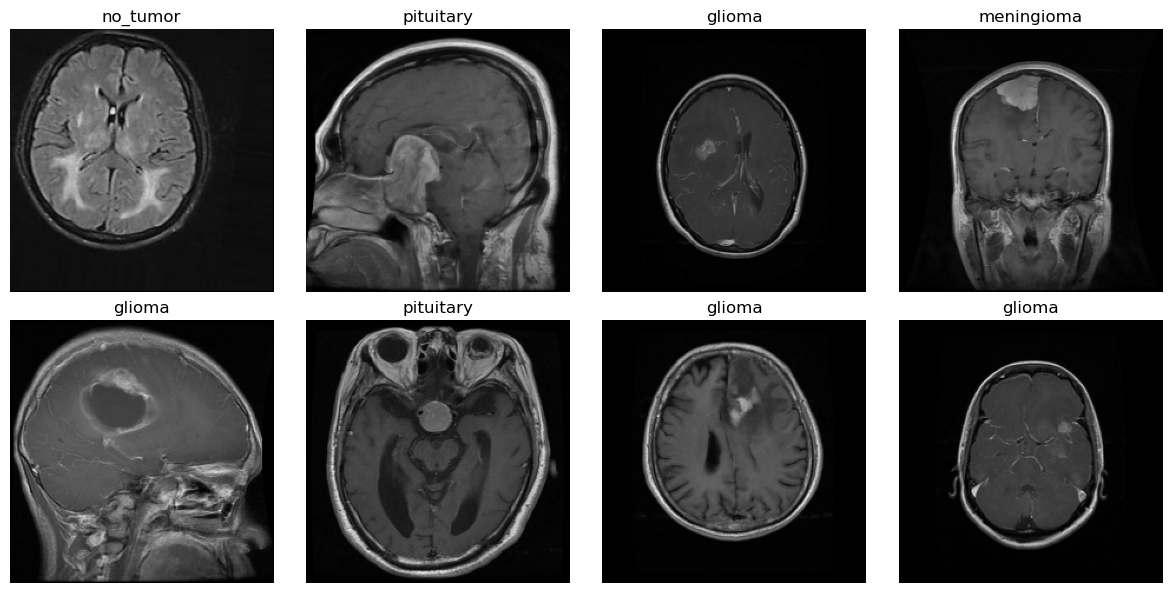

In [30]:
images, labels = next(iter(train_ds))

plt.figure(figsize=(12, 6))

for i in range(min(8, len(images))):
    plt.subplot(2, 4, i + 1)

    plt.imshow(images[i].numpy())

    class_name = CLASSES[int(labels[i].numpy())]

    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [31]:

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(
        factor=0.03
    ),

    tf.keras.layers.RandomZoom(
        height_factor=0.08,
        width_factor=0.08
    ),

    tf.keras.layers.RandomContrast(
        factor=0.1,
        value_range=(0, 1)
    )
], name="data_augmentation")


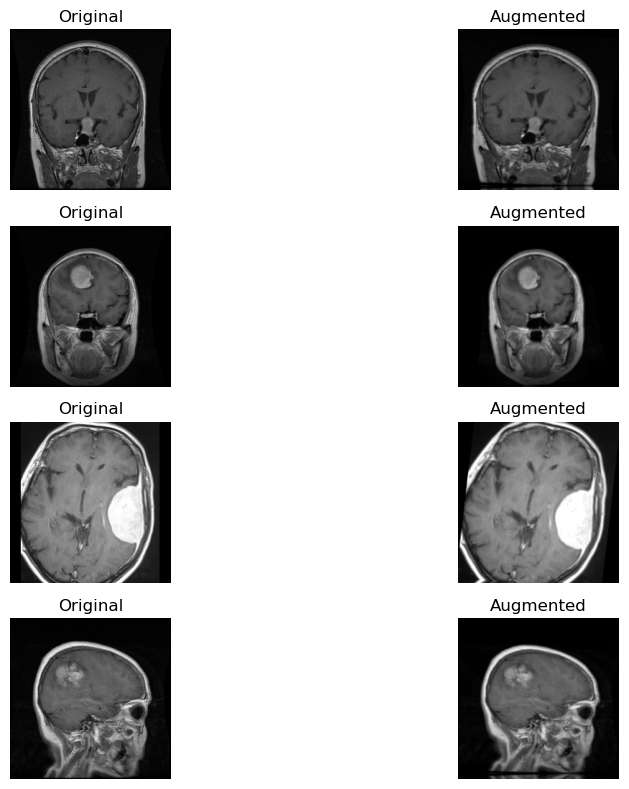

In [32]:
images, labels = next(iter(train_ds))

plt.figure(figsize=(12, 8))

for i in range(4):
    original = images[i]

    augmented = data_augmentation(
        tf.expand_dims(original, axis=0),
        training=True
    )[0]

    # Original image
    plt.subplot(4, 2, 2*i + 1)
    plt.imshow(original.numpy())
    plt.title("Original")
    plt.axis("off")

    # Augmented image
    plt.subplot(4, 2, 2*i + 2)
    plt.imshow(
        tf.clip_by_value(augmented, 0, 1).numpy()
    )
    plt.title("Augmented")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [33]:
from tensorflow.keras import layers, models

NUM_CLASSES = 4

cnn_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    # Block 1
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Block 2
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Block 3
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Block 4
    layers.Conv2D(256, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Classification
    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),

    layers.Dense(NUM_CLASSES, activation="softmax")
])

cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,828 (1.61 MB)

 Trainable params: 421,828 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

In [34]:
cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]
)

print("CNN model compiled successfully!")

CNN model compiled successfully!


In [35]:
total_params = cnn_model.count_params()

print("Total parameters:", total_params)

Total parameters: 421828


In [38]:
with open(
    "cnn_model_summary.txt",
    "w",
    encoding="utf-8"
) as f:
    cnn_model.summary(
        print_fn=lambda x: f.write(x + "\n")
    )

print("Model summary saved successfully!")

Model summary saved successfully!


In [39]:
def augment_image(image, label):
    image = data_augmentation(
        image,
        training=True
    )
    return image, label

train_ds_aug = (
    train_ds
    .map(augment_image, num_parallel_calls=AUTOTUNE)
    .prefetch(AUTOTUNE)
)

In [40]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=0.00001
    ),

    ModelCheckpoint(
        "best_cnn_model.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

print("Training callbacks configured!")

Training callbacks configured!


In [41]:
history = cnn_model.fit(
    train_ds_aug,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks
)

Epoch 1/15


D:\anaconda\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


496/496 ━━━━━━━━━━━━━━━━━━━━ 142s 280ms/step - accuracy: 0.4316 - loss: 1.2540 - val_accuracy: 0.4854 - val_loss: 1.2000 - learning_rate: 0.0010
Epoch 2/15
496/496 ━━━━━━━━━━━━━━━━━━━━ 137s 275ms/step - accuracy: 0.5257 - loss: 1.0906 - val_accuracy: 0.5530 - val_loss: 1.0617 - learning_rate: 0.0010
Epoch 3/15
496/496 ━━━━━━━━━━━━━━━━━━━━ 129s 260ms/step - accuracy: 0.6239 - loss: 0.8923 - val_accuracy: 0.7366 - val_loss: 0.7574 - learning_rate: 0.0010
Epoch 4/15
496/496 ━━━━━━━━━━━━━━━━━━━━ 145s 292ms/step - accuracy: 0.6655 - loss: 0.8137 - val_accuracy: 0.6993 - val_loss: 0.7842 - learning_rate: 0.0010
Epoch 5/15
496/496 ━━━━━━━━━━━━━━━━━━━━ 127s 256ms/step - accuracy: 0.6847 - loss: 0.7473 - val_accuracy: 0.7003 - val_loss: 0.7850 - learning_rate: 0.0010
Epoch 6/15
496/496 ━━━━━━━━━━━━━━━━━━━━ 150s 302ms/step - accuracy: 0.7154 - loss: 0.6900 - val_accuracy: 0.6498 - val_loss: 0.7934 - learning_rate: 5.0000e-04
Epoch 7/15
496/496 ━━━━━━━━━━━━━━━━━━━━ 148s 297ms/step - accuracy: 0.7

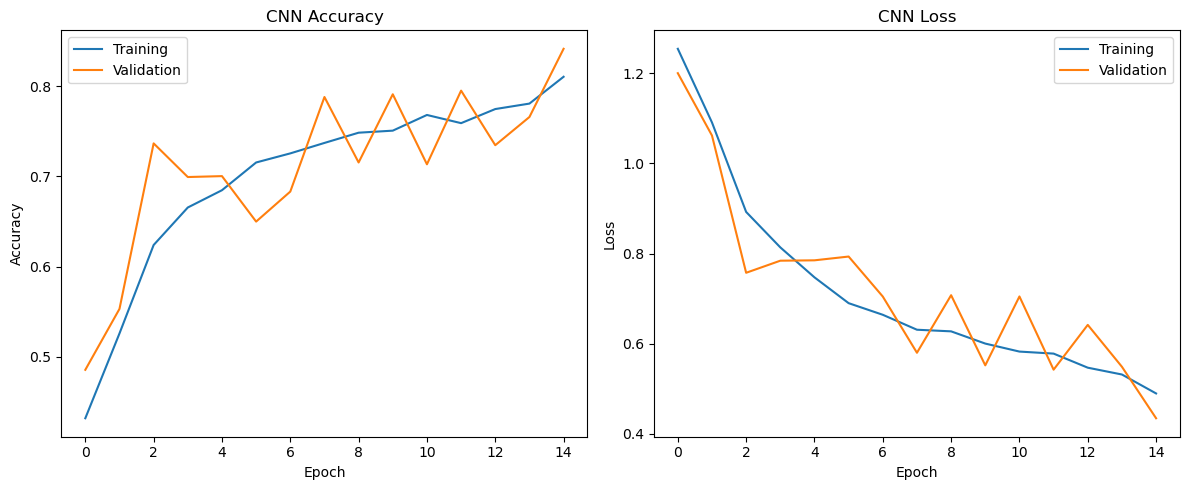

In [42]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [43]:
best_cnn = tf.keras.models.load_model(
    "best_cnn_model.keras"
)

print("Best CNN model loaded!")

Best CNN model loaded!


In [44]:
import numpy as np

y_true = val_labels

y_prob = best_cnn.predict(val_ds)

y_pred = np.argmax(y_prob, axis=1)

print("Predictions completed!")
print("Number of predictions:", len(y_pred))

124/124 ━━━━━━━━━━━━━━━━━━━━ 9s 68ms/step
Predictions completed!
Number of predictions: 991


In [45]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_true,
        y_pred,
        target_names=CLASSES,
        digits=4
    )
)

              precision    recall  f1-score   support

      glioma     0.8864    0.6812    0.7704       229
  meningioma     0.7256    0.7672    0.7458       262
    no_tumor     0.9384    0.9340    0.9362       212
   pituitary     0.8532    0.9688    0.9073       288

    accuracy                         0.8416       991
   macro avg     0.8509    0.8378    0.8399       991
weighted avg     0.8454    0.8416    0.8391       991



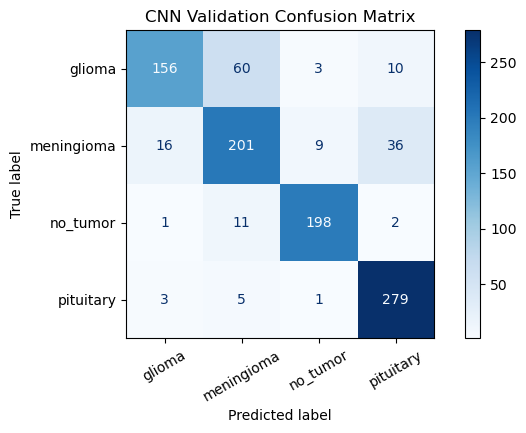

In [47]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_true,
    y_pred
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASSES
)

fig, ax = plt.subplots(figsize=(8, 4))

display.plot(
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title("CNN Validation Confusion Matrix")
plt.xticks(rotation=30)
plt.show()

In [48]:
import json

best_cnn.save("baseline_cnn_model.keras")

with open("cnn_validation_report.json", "w") as f:
    json.dump(
        classification_report(
            y_true,
            y_pred,
            target_names=CLASSES,
            output_dict=True
        ),
        f,
        indent=4
    )

print("Baseline CNN and evaluation report saved!")

Baseline CNN and evaluation report saved!


In [49]:
from tensorflow.keras.applications import MobileNetV2

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

print("MobileNetV2 loaded!")
print("Base model layers:", len(base_model.layers))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
MobileNetV2 loaded!
Base model layers: 154


In [50]:
from tensorflow.keras import layers, Model

inputs = layers.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)

# Convert [0, 1] to [-1, 1]
x = layers.Rescaling(
    scale=2.0,
    offset=-1.0
)(x)

x = base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.3)(x)

x = layers.Dense(
    128,
    activation="relu"
)(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    4,
    activation="softmax"
)(x)

mobilenet_model = Model(
    inputs=inputs,
    outputs=outputs
)

mobilenet_model.summary()

Model: "functional_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,468 (9.24 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [51]:
mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("MobileNetV2 compiled successfully!")

MobileNetV2 compiled successfully!


In [52]:
mobilenet_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=0.000001
    ),

    tf.keras.callbacks.ModelCheckpoint(
        "best_mobilenet_model.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

In [53]:
mobilenet_history = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=12,
    callbacks=mobilenet_callbacks
)

Epoch 1/12


D:\anaconda\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


496/496 ━━━━━━━━━━━━━━━━━━━━ 123s 234ms/step - accuracy: 0.6367 - loss: 0.9027 - val_accuracy: 0.7820 - val_loss: 0.5730 - learning_rate: 1.0000e-04
Epoch 2/12
496/496 ━━━━━━━━━━━━━━━━━━━━ 116s 233ms/step - accuracy: 0.7876 - loss: 0.5571 - val_accuracy: 0.8123 - val_loss: 0.4935 - learning_rate: 1.0000e-04
Epoch 3/12
496/496 ━━━━━━━━━━━━━━━━━━━━ 138s 278ms/step - accuracy: 0.8257 - loss: 0.4621 - val_accuracy: 0.8365 - val_loss: 0.4538 - learning_rate: 1.0000e-04
Epoch 4/12
496/496 ━━━━━━━━━━━━━━━━━━━━ 126s 254ms/step - accuracy: 0.8317 - loss: 0.4358 - val_accuracy: 0.8567 - val_loss: 0.4150 - learning_rate: 1.0000e-04
Epoch 5/12
496/496 ━━━━━━━━━━━━━━━━━━━━ 152s 306ms/step - accuracy: 0.8544 - loss: 0.3900 - val_accuracy: 0.8375 - val_loss: 0.4593 - learning_rate: 1.0000e-04
Epoch 6/12
496/496 ━━━━━━━━━━━━━━━━━━━━ 134s 269ms/step - accuracy: 0.8650 - loss: 0.3541 - val_accuracy: 0.8698 - val_loss: 0.3824 - learning_rate: 1.0000e-04
Epoch 7/12
496/496 ━━━━━━━━━━━━━━━━━━━━ 103s 207ms/

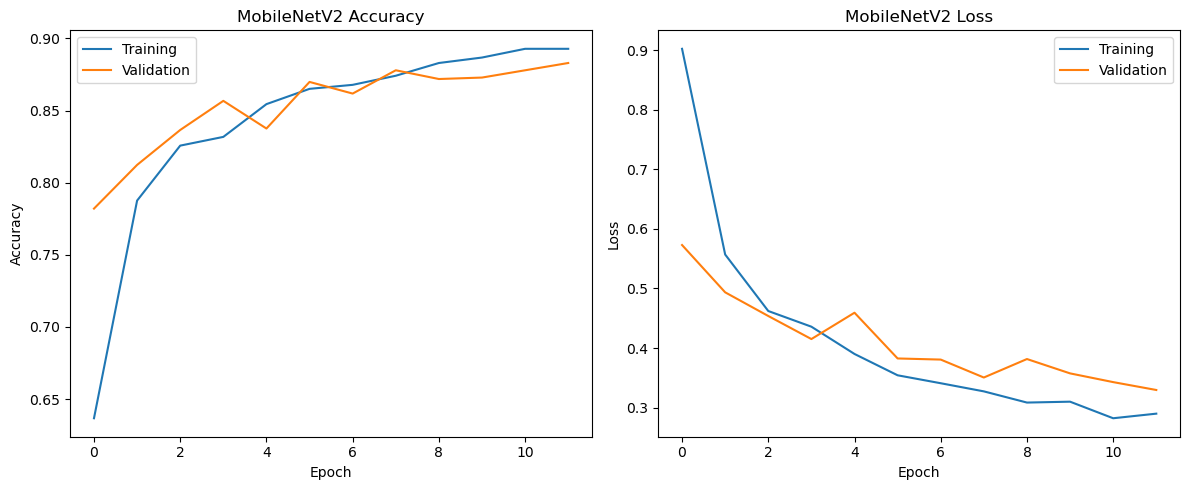

In [54]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(
    mobilenet_history.history["accuracy"],
    label="Training"
)
plt.plot(
    mobilenet_history.history["val_accuracy"],
    label="Validation"
)
plt.title("MobileNetV2 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(
    mobilenet_history.history["loss"],
    label="Training"
)
plt.plot(
    mobilenet_history.history["val_loss"],
    label="Validation"
)
plt.title("MobileNetV2 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [55]:
best_mobilenet = tf.keras.models.load_model(
    "best_mobilenet_model.keras"
)

print("Best MobileNetV2 loaded!")

Best MobileNetV2 loaded!


In [56]:
mobilenet_y_prob = best_mobilenet.predict(val_ds)

mobilenet_y_pred = np.argmax(
    mobilenet_y_prob,
    axis=1
)

print("Predictions completed!")

124/124 ━━━━━━━━━━━━━━━━━━━━ 26s 195ms/step
Predictions completed!


In [57]:
from sklearn.metrics import classification_report

print(
    classification_report(
        val_labels,
        mobilenet_y_pred,
        target_names=CLASSES,
        digits=4
    )
)

              precision    recall  f1-score   support

      glioma     0.9261    0.8210    0.8704       229
  meningioma     0.7829    0.8397    0.8103       262
    no_tumor     0.9740    0.8821    0.9257       212
   pituitary     0.8889    0.9722    0.9287       288

    accuracy                         0.8829       991
   macro avg     0.8930    0.8787    0.8838       991
weighted avg     0.8877    0.8829    0.8833       991



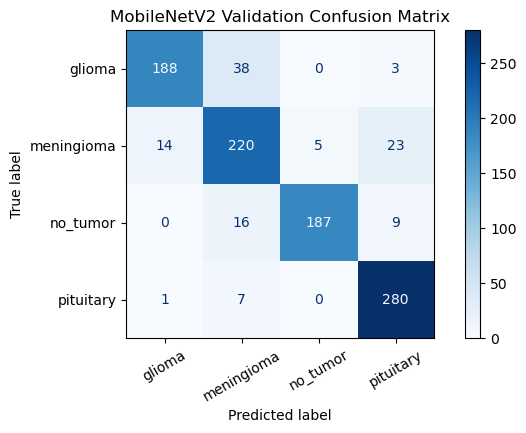

In [59]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

mobilenet_cm = confusion_matrix(
    val_labels,
    mobilenet_y_pred
)

fig, ax = plt.subplots(figsize=(8, 4))

disp = ConfusionMatrixDisplay(
    confusion_matrix=mobilenet_cm,
    display_labels=CLASSES
)

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title("MobileNetV2 Validation Confusion Matrix")
plt.xticks(rotation=30)
plt.show()

In [60]:
best_mobilenet = tf.keras.models.load_model(
    "best_mobilenet_model.keras"
)

print("Best MobileNetV2 loaded!")

Best MobileNetV2 loaded!


In [61]:
base_model = best_mobilenet.get_layer(
    "mobilenetv2_1.00_224"
)

base_model.trainable = True

# Freeze all but the final 30 layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep BatchNormalization layers frozen
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

print(
    "Trainable base layers:",
    sum(layer.trainable for layer in base_model.layers)
)

Trainable base layers: 19


In [62]:
best_mobilenet.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Fine-tuning model compiled!")

Fine-tuning model compiled!


In [63]:
fine_tune_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ModelCheckpoint(
        "best_finetuned_model.keras",
        monitor="val_loss",
        save_best_only=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7
    )
]

fine_tune_history = best_mobilenet.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=fine_tune_callbacks
)

Epoch 1/8


D:\anaconda\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


496/496 ━━━━━━━━━━━━━━━━━━━━ 145s 276ms/step - accuracy: 0.9021 - loss: 0.2707 - val_accuracy: 0.8708 - val_loss: 0.3722 - learning_rate: 1.0000e-05
Epoch 2/8
496/496 ━━━━━━━━━━━━━━━━━━━━ 124s 250ms/step - accuracy: 0.9122 - loss: 0.2314 - val_accuracy: 0.8930 - val_loss: 0.2793 - learning_rate: 1.0000e-05
Epoch 3/8
496/496 ━━━━━━━━━━━━━━━━━━━━ 161s 324ms/step - accuracy: 0.9213 - loss: 0.2026 - val_accuracy: 0.8971 - val_loss: 0.2786 - learning_rate: 1.0000e-05
Epoch 4/8
496/496 ━━━━━━━━━━━━━━━━━━━━ 127s 256ms/step - accuracy: 0.9321 - loss: 0.1719 - val_accuracy: 0.9112 - val_loss: 0.2252 - learning_rate: 1.0000e-05
Epoch 5/8
496/496 ━━━━━━━━━━━━━━━━━━━━ 460s 929ms/step - accuracy: 0.9448 - loss: 0.1520 - val_accuracy: 0.9122 - val_loss: 0.2338 - learning_rate: 1.0000e-05
Epoch 6/8
496/496 ━━━━━━━━━━━━━━━━━━━━ 125s 252ms/step - accuracy: 0.9528 - loss: 0.1307 - val_accuracy: 0.9193 - val_loss: 0.2189 - learning_rate: 1.0000e-05
Epoch 7/8
496/496 ━━━━━━━━━━━━━━━━━━━━ 128s 259ms/step -

In [64]:
best_finetuned = tf.keras.models.load_model(
    "best_finetuned_model.keras"
)

print("Best fine-tuned model loaded!")

Best fine-tuned model loaded!


In [65]:
finetuned_prob = best_finetuned.predict(val_ds)

finetuned_pred = np.argmax(
    finetuned_prob,
    axis=1
)

124/124 ━━━━━━━━━━━━━━━━━━━━ 31s 224ms/step


In [66]:
from sklearn.metrics import classification_report

finetuned_report = classification_report(
    val_labels,
    finetuned_pred,
    target_names=CLASSES,
    digits=4
)

print(finetuned_report)

              precision    recall  f1-score   support

      glioma     0.9442    0.8865    0.9144       229
  meningioma     0.8831    0.8359    0.8588       262
    no_tumor     0.9854    0.9528    0.9688       212
   pituitary     0.8885    0.9965    0.9394       288

    accuracy                         0.9193       991
   macro avg     0.9253    0.9179    0.9204       991
weighted avg     0.9207    0.9193    0.9186       991



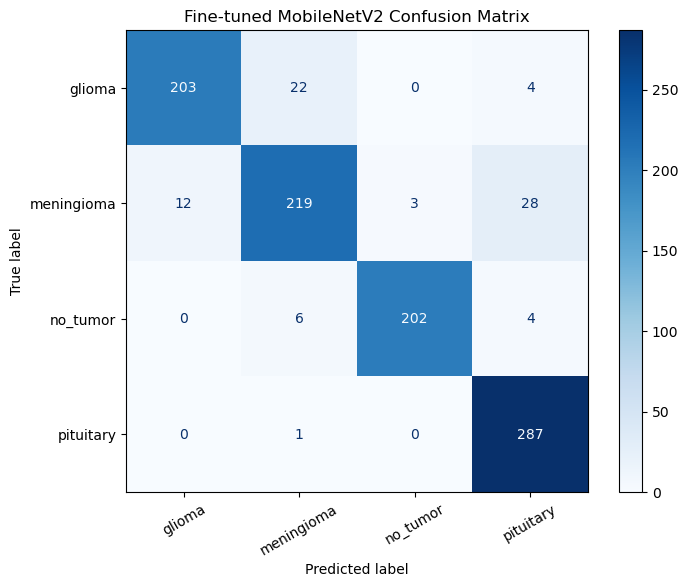

In [67]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

finetuned_cm = confusion_matrix(
    val_labels,
    finetuned_pred
)

fig, ax = plt.subplots(figsize=(8, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=finetuned_cm,
    display_labels=CLASSES
)

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title("Fine-tuned MobileNetV2 Confusion Matrix")
plt.xticks(rotation=30)
plt.show()

In [68]:
best_finetuned.save(
    "final_brain_tumor_model.keras"
)

print("Final candidate model saved!")

Final candidate model saved!


In [69]:
best_finetuned.save(
    "final_brain_tumor_model.keras"
)

print("Fine-tuned model saved successfully!")

Fine-tuned model saved successfully!


In [70]:
# Get the MobileNetV2 base model
base_model = best_finetuned.get_layer(
    "mobilenetv2_1.00_224"
)

# Reconstruct the model path so we can access
# both convolutional features and predictions
inputs = best_finetuned.input

x = best_finetuned.get_layer("sequential")(inputs)
x = best_finetuned.get_layer("rescaling")(x)

feature_maps = base_model(x, training=False)

x = best_finetuned.get_layer(
    "global_average_pooling2d_1"
)(feature_maps)

x = best_finetuned.get_layer("dropout_1")(x, training=False)
x = best_finetuned.get_layer("dense_2")(x)
x = best_finetuned.get_layer("dropout_2")(x, training=False)

predictions = best_finetuned.get_layer("dense_3")(x)

grad_model = tf.keras.Model(
    inputs=inputs,
    outputs=[feature_maps, predictions]
)

print("Grad-CAM model created!")

Grad-CAM model created!


In [71]:
def generate_gradcam(image_tensor, model):

    with tf.GradientTape() as tape:

        conv_outputs, predictions = model(
            image_tensor,
            training=False
        )

        predicted_class = tf.argmax(
            predictions[0]
        )

        class_score = predictions[:, predicted_class]

    gradients = tape.gradient(
        class_score,
        conv_outputs
    )

    # Average gradients across spatial dimensions
    weights = tf.reduce_mean(
        gradients,
        axis=(0, 1, 2)
    )

    # Weighted combination of feature maps
    cam = tf.reduce_sum(
        conv_outputs[0] * weights,
        axis=-1
    )

    # Keep positive activations
    cam = tf.maximum(cam, 0)

    # Normalize heatmap
    cam = cam / (
        tf.reduce_max(cam) + 1e-8
    )

    return cam.numpy(), predictions.numpy()[0]

In [72]:
# Get one validation batch
images, labels = next(iter(val_ds))

# Select the first image
sample_image = images[0:1]
actual_label = int(labels[0].numpy())

# Generate heatmap
heatmap, probabilities = generate_gradcam(
    sample_image,
    grad_model
)

predicted_label = int(np.argmax(probabilities))

print("Actual class:", CLASSES[actual_label])
print("Predicted class:", CLASSES[predicted_label])
print(
    "Confidence:",
    round(float(probabilities[predicted_label]) * 100, 2),
    "%"
)

Actual class: meningioma
Predicted class: meningioma
Confidence: 57.96 %


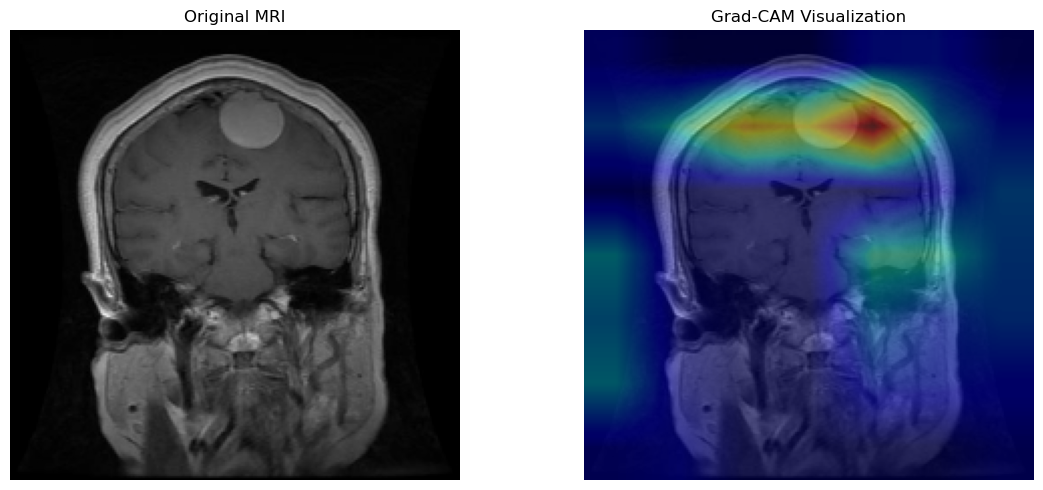

In [73]:
# Resize heatmap to original image size
heatmap_resized = tf.image.resize(
    heatmap[..., np.newaxis],
    (224, 224)
).numpy().squeeze()

original_image = sample_image[0].numpy()

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.title("Original MRI")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(original_image)
plt.imshow(
    heatmap_resized,
    cmap="jet",
    alpha=0.4
)
plt.title("Grad-CAM Visualization")
plt.axis("off")

plt.tight_layout()
plt.show()

In [74]:
print("Test images:", test_df.shape[0])
print("Classes:", CLASSES)
print("Test dataset available:", "test_ds" in globals())

Test images: 1000
Classes: ['glioma', 'meningioma', 'no_tumor', 'pituitary']
Test dataset available: False


In [78]:
import tensorflow as tf
import numpy as np

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 8

# Convert class names into numerical labels
class_to_index = {
    name: index for index, name in enumerate(CLASSES)
}

# Get image paths and labels from the test manifest
test_paths = test_df["filepath"].astype(str).values

test_labels = test_df["tumor_label"].map(
    class_to_index
).values.astype("int32")

# Load and resize images
def load_test_image(filepath, label):
    image = tf.io.read_file(filepath)

    image = tf.io.decode_jpeg(
        image,
        channels=3
    )

    image = tf.image.resize(
        image,
        IMAGE_SIZE
    )

    return image, label

# Create the test dataset
test_ds = tf.data.Dataset.from_tensor_slices(
    (test_paths, test_labels)
)

test_ds = test_ds.map(
    load_test_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_ds = test_ds.batch(BATCH_SIZE)
test_ds = test_ds.prefetch(tf.data.AUTOTUNE)

print("Test dataset created successfully!")
print("Number of test images:", len(test_paths))
print("Classes:", CLASSES)

Test dataset created successfully!
Number of test images: 1000
Classes: ['glioma', 'meningioma', 'no_tumor', 'pituitary']


In [79]:
for images, labels in test_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Image value range:",
          float(tf.reduce_min(images)),
          "to",
          float(tf.reduce_max(images)))

Image batch shape: (8, 224, 224, 3)
Label batch shape: (8,)
Image value range: 0.0 to 251.43392944335938


In [80]:
test_predictions = best_finetuned.predict(test_ds)

y_pred = np.argmax(test_predictions, axis=1)

y_true = np.concatenate([
    labels.numpy()
    for images, labels in test_ds
])

print("Predictions completed!")
print("Predictions:", len(y_pred))
print("Actual labels:", len(y_true))

125/125 ━━━━━━━━━━━━━━━━━━━━ 23s 187ms/step
Predictions completed!
Predictions: 1000
Actual labels: 1000


In [81]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Calculate accuracy
test_accuracy = accuracy_score(y_true, y_pred)

print("FINAL TEST ACCURACY:",
      round(test_accuracy * 100, 2), "%")

# Classification report
print("\nFINAL TEST CLASSIFICATION REPORT:\n")

print(classification_report(
    y_true,
    y_pred,
    labels=range(len(CLASSES)),
    target_names=CLASSES,
    digits=4
))

FINAL TEST ACCURACY: 15.3 %

FINAL TEST CLASSIFICATION REPORT:

              precision    recall  f1-score   support

      glioma     0.0000    0.0000    0.0000       254
  meningioma     0.4000    0.0327    0.0604       306
    no_tumor     0.1440    1.0000    0.2518       140
   pituitary     1.0000    0.0100    0.0198       300

    accuracy                         0.1530      1000
   macro avg     0.3860    0.2607    0.0830      1000
weighted avg     0.4426    0.1530    0.0597      1000



D:\anaconda\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
D:\anaconda\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
D:\anaconda\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


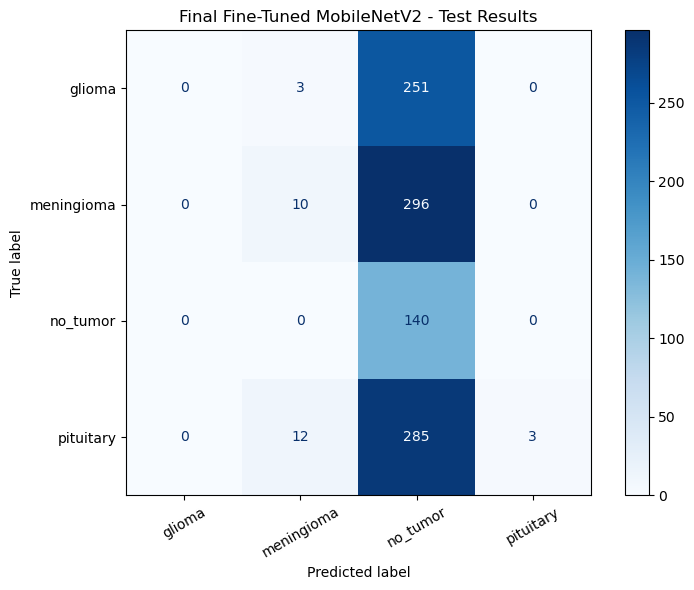

In [82]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=range(len(CLASSES))
)

fig, ax = plt.subplots(figsize=(8, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASSES
)

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title("Final Fine-Tuned MobileNetV2 - Test Results")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [83]:
# 1. Inspect the model's preprocessing layers
print("MODEL PREPROCESSING LAYERS\n")

for layer in best_finetuned.layers:
    if isinstance(layer, tf.keras.Sequential) or "rescal" in layer.name.lower():
        print("\nLayer:", layer.name)
        print("Configuration:", layer.get_config())

# 2. Compare validation and test image ranges
val_images, val_labels = next(iter(val_ds))
test_images, test_labels = next(iter(test_ds))

print("\nIMAGE COMPARISON")
print("Validation range:",
      float(tf.reduce_min(val_images)),
      "to",
      float(tf.reduce_max(val_images)))

print("Test range:",
      float(tf.reduce_min(test_images)),
      "to",
      float(tf.reduce_max(test_images)))

# 3. Compare predictions on both datasets
val_probs = best_finetuned.predict(val_images, verbose=0)
test_probs = best_finetuned.predict(test_images, verbose=0)

print("\nPREDICTION CLASS DISTRIBUTION")

print("Validation predictions:",
      np.bincount(np.argmax(val_probs, axis=1),
                  minlength=len(CLASSES)))

print("Test predictions:",
      np.bincount(np.argmax(test_probs, axis=1),
                  minlength=len(CLASSES)))

print("\nCLASS ORDER:", CLASSES)

MODEL PREPROCESSING LAYERS


Layer: sequential
Configuration: {'name': 'sequential', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name': None}, 'layers': [{'module': 'keras.layers', 'class_name': 'InputLayer', 'config': {'batch_shape': (1, 224, 224, 3), 'dtype': 'float32', 'sparse': False, 'ragged': False, 'name': 'input_layer', 'optional': False}, 'registered_name': None}, {'module': 'keras.layers', 'class_name': 'RandomRotation', 'config': {'name': 'random_rotation', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name': None}, 'data_format': 'channels_last', 'factor': (-0.03, 0.03), 'fill_mode': 'reflect', 'fill_value': 0.0, 'interpolation': 'bilinear', 'seed': None}, 'registered_name': None, 'build_config': {'input_shape': [1, 224, 224, 3]}}, {'module': 'keras.layers', 'class_name': 'RandomZoom', 'config': {'name': 'random_zoom', 'traina

In [84]:
print("Test label distribution:")

print(
    test_df["tumor_label"].value_counts()
)

print("\nNumerical label mapping:")

for index, name in enumerate(CLASSES):
    print(index, "=", name)

Test label distribution:
tumor_label
meningioma    306
pituitary     300
glioma        254
no_tumor      140
Name: count, dtype: int64

Numerical label mapping:
0 = glioma
1 = meningioma
2 = no_tumor
3 = pituitary


In [85]:
def load_test_image(filepath, label):
    image = tf.io.read_file(filepath)

    image = tf.io.decode_jpeg(
        image,
        channels=3
    )

    image = tf.image.resize(
        image,
        (224, 224)
    )

    # Match the validation preprocessing
    image = image / 255.0

    return image, label

In [86]:
test_ds = tf.data.Dataset.from_tensor_slices(
    (test_paths, test_labels)
)

test_ds = test_ds.map(
    load_test_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_ds = test_ds.batch(8)
test_ds = test_ds.prefetch(tf.data.AUTOTUNE)

print("Corrected test dataset created!")

ValueError: Dimensions 1000 and 8 are not compatible

In [87]:
# Recreate test image paths
test_paths = test_df["filepath"].astype(str).values

# Recreate all 1000 numerical labels
class_to_index = {
    name: index for index, name in enumerate(CLASSES)
}

test_labels = test_df["tumor_label"].map(
    class_to_index
).values.astype("int32")

# Verify lengths
print("Test paths:", len(test_paths))
print("Test labels:", len(test_labels))

assert len(test_paths) == len(test_labels) == 1000

print("Test variables verified!")

Test paths: 1000
Test labels: 1000
Test variables verified!


In [88]:
test_ds = tf.data.Dataset.from_tensor_slices(
    (test_paths, test_labels)
)

test_ds = test_ds.map(
    load_test_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_ds = test_ds.batch(8)
test_ds = test_ds.prefetch(tf.data.AUTOTUNE)

print("Corrected test dataset created!")

Corrected test dataset created!


In [89]:
for images, labels in test_ds.take(1):
    print("Image shape:", images.shape)
    print("Label shape:", labels.shape)
    print(
        "Pixel range:",
        float(tf.reduce_min(images)),
        "to",
        float(tf.reduce_max(images))
    )

Image shape: (8, 224, 224, 3)
Label shape: (8,)
Pixel range: 0.0 to 0.9860154390335083


In [90]:
from pathlib import Path

MODEL_DIR = PROJECT_PATH / "models"
MODEL_DIR.mkdir(exist_ok=True)

# Save the baseline CNN
cnn_model.save(MODEL_DIR / "baseline_cnn.keras")

# Save the fine-tuned MobileNetV2
best_finetuned.save(MODEL_DIR / "brain_tumor_mobilenetv2.keras")

print("Both models saved successfully!")

Both models saved successfully!


In [4]:
from pathlib import Path
import tensorflow as tf

PROJECT_PATH = Path(
    r"C:\Users\Chaithanya Reddy\Projects\Brain_Tumor_AI_Project"
)

MODEL_PATH = PROJECT_PATH / "best_finetuned_model.keras"

best_finetuned = tf.keras.models.load_model(MODEL_PATH)

print("Model loaded successfully!")
best_finetuned.summary()

Model loaded successfully!


Model: "functional_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,772,878 (22.02 MB)

 Trainable params: 1,675,204 (6.39 MB)

 Non-trainable params: 747,264 (2.85 MB)

 Optimizer params: 3,350,410 (12.78 MB)

In [5]:
import pandas as pd
import numpy as np

CLASSES = ["glioma", "meningioma", "no_tumor", "pituitary"]

test_df = pd.read_csv(
    PROJECT_PATH / "processed_data" / "test_manifest.csv"
)

if "filepath" not in test_df.columns:
    DATASET_PATH = PROJECT_PATH / "brain_tumor"

    def make_filepath(relative_path):
        parts = str(relative_path).replace("\\", "/").split("/")
        return str(DATASET_PATH.joinpath(*parts))

    test_df["filepath"] = test_df["relative_path"].apply(make_filepath)

test_paths = test_df["filepath"].astype(str).values

class_to_index = {name: index for index, name in enumerate(CLASSES)}

test_labels = (
    test_df["tumor_label"]
    .map(class_to_index)
    .values.astype("int32")
)

print("Test images:", len(test_paths))
print("Test labels:", len(test_labels))

Test images: 1000
Test labels: 1000


In [6]:
def load_test_image(filepath, label):
    image = tf.io.read_file(filepath)
    image = tf.io.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, (224, 224))
    image = image / 255.0
    return image, label

test_ds = tf.data.Dataset.from_tensor_slices(
    (test_paths, test_labels)
)

test_ds = (
    test_ds
    .map(load_test_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(8)
    .prefetch(tf.data.AUTOTUNE)
)

print("Test dataset ready:", test_ds)

Test dataset ready: <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>


In [7]:
test_loss, test_accuracy = best_finetuned.evaluate(test_ds)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

125/125 ━━━━━━━━━━━━━━━━━━━━ 41s 255ms/step - accuracy: 0.8990 - loss: 0.2776
Test Loss: 0.2776
Test Accuracy: 89.90%


In [8]:
from sklearn.metrics import classification_report
import numpy as np

# Generate predictions
test_probabilities = best_finetuned.predict(test_ds)

# Convert probabilities into predicted class indices
y_pred = np.argmax(test_probabilities, axis=1)

# Get actual labels
y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

# Classification report
print(classification_report(
    y_true,
    y_pred,
    target_names=CLASSES,
    digits=4
))

125/125 ━━━━━━━━━━━━━━━━━━━━ 36s 256ms/step
              precision    recall  f1-score   support

      glioma     0.9591    0.8307    0.8903       254
  meningioma     0.8707    0.8366    0.8533       306
    no_tumor     0.9504    0.9571    0.9537       140
   pituitary     0.8638    0.9933    0.9240       300

    accuracy                         0.8990      1000
   macro avg     0.9110    0.9044    0.9053      1000
weighted avg     0.9022    0.8990    0.8980      1000



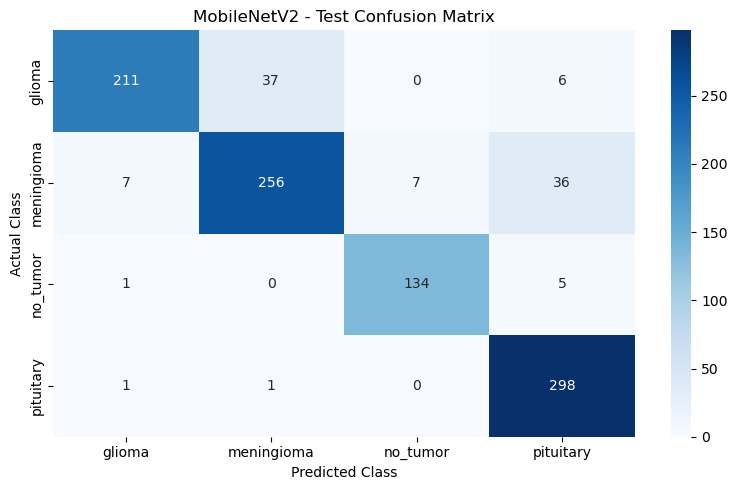

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASSES,
    yticklabels=CLASSES
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("MobileNetV2 - Test Confusion Matrix")
plt.tight_layout()
plt.show()

In [27]:
import json
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix

RESULTS_DIR = PROJECT_PATH / "results"
RESULTS_DIR.mkdir(exist_ok=True)

# Save classification report
report = classification_report(
    y_true,
    y_pred,
    target_names=CLASSES,
    output_dict=True
)

with open(RESULTS_DIR / "test_classification_report.json", "w") as f:
    json.dump(report, f, indent=4)

# Save confusion matrix
cm = confusion_matrix(y_true, y_pred)

pd.DataFrame(
    cm,
    index=CLASSES,
    columns=CLASSES
).to_csv(RESULTS_DIR / "test_confusion_matrix.csv")

# Save summary
summary = {
    "model": "Fine-tuned MobileNetV2",
    "test_accuracy": float(test_accuracy),
    "test_loss": float(test_loss),
    "test_images": len(y_true),
    "macro_f1": report["macro avg"]["f1-score"],
    "weighted_f1": report["weighted avg"]["f1-score"]
}

with open(RESULTS_DIR / "test_summary.json", "w") as f:
    json.dump(summary, f, indent=4)

print("Evaluation results saved successfully!")

Evaluation results saved successfully!


In [28]:

# STEP 1: Consistent test preprocessing

IMAGE_SIZE = 224
BATCH_SIZE = 8

def load_test_image_corrected(filepath, label):
    image = tf.io.read_file(filepath)

    image = tf.io.decode_jpeg(
        image,
        channels=3
    )

    # Match training preprocessing
    image = tf.image.resize_with_pad(
        image,
        IMAGE_SIZE,
        IMAGE_SIZE
    )

    # Match training normalization
    image = tf.cast(image, tf.float32) / 255.0

    return image, label


corrected_test_ds = (
    tf.data.Dataset.from_tensor_slices(
        (test_paths, test_labels)
    )
    .map(
        load_test_image_corrected,
        num_parallel_calls=tf.data.AUTOTUNE
    )
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

# Verify pixel range
for images, labels in corrected_test_ds.take(1):
    print("Image shape:", images.shape)
    print("Label shape:", labels.shape)
    print("Pixel minimum:", float(tf.reduce_min(images)))
    print("Pixel maximum:", float(tf.reduce_max(images)))


Image shape: (8, 224, 224, 3)
Label shape: (8,)
Pixel minimum: 0.0
Pixel maximum: 0.985649585723877


In [29]:

# Load the existing tested model
model = tf.keras.models.load_model(
    "best_finetuned_model.keras"
)

# Evaluate using corrected preprocessing
corrected_loss, corrected_accuracy = model.evaluate(
    corrected_test_ds
)

print(f"Corrected Test Loss: {corrected_loss:.4f}")
print(f"Corrected Test Accuracy: {corrected_accuracy * 100:.2f}%")


125/125 ━━━━━━━━━━━━━━━━━━━━ 39s 253ms/step - accuracy: 0.9170 - loss: 0.2407
Corrected Test Loss: 0.2407
Corrected Test Accuracy: 91.70%


In [37]:

import tensorflow as tf
import pandas as pd
from pathlib import Path

# Project and dataset paths
PROJECT_PATH = Path(
    r"C:\Users\Chaithanya Reddy\Projects\Brain_Tumor_AI_Project"
)

OUTPUT_PATH = PROJECT_PATH / "processed_data"

# Load previously saved splits
train_split = pd.read_csv(
    OUTPUT_PATH / "train_split.csv"
)

val_split = pd.read_csv(
    OUTPUT_PATH / "validation_split.csv"
)

print("Training images:", len(train_split))
print("Validation images:", len(val_split))

print("\nTraining columns:", train_split.columns.tolist())
print("Validation columns:", val_split.columns.tolist())

# Model configuration
IMG_SIZE = 224
BATCH_SIZE = 8
AUTOTUNE = tf.data.AUTOTUNE

CLASSES = [
    "glioma",
    "meningioma",
    "no_tumor",
    "pituitary"
]

# Convert labels into numerical values
class_to_index = {
    name: index
    for index, name in enumerate(CLASSES)
}

def prepare_dataframe(df):
    paths = df["filepath"].astype(str).values

    labels = (
        df["tumor_label"]
        .map(class_to_index)
        .astype("int32")
        .values
    )

    return paths, labels

train_paths, train_labels = prepare_dataframe(train_split)
val_paths, val_labels = prepare_dataframe(val_split)

# Check image paths
print("\nAll training paths exist:",
      all(Path(p).is_file() for p in train_paths))

print("All validation paths exist:",
      all(Path(p).is_file() for p in val_paths))


Training images: 3964
Validation images: 991

Training columns: ['relative_path', 'filename', 'task', 'split', 'index', 'tumor_code', 'tumor_label', 'plane_code', 'plane_label', 'sequence', 'is_mask', 'linked_image', 'width', 'height', 'file_size_bytes', 'sha256', 'dimensions', 'filepath']
Validation columns: ['relative_path', 'filename', 'task', 'split', 'index', 'tumor_code', 'tumor_label', 'plane_code', 'plane_label', 'sequence', 'is_mask', 'linked_image', 'width', 'height', 'file_size_bytes', 'sha256', 'dimensions', 'filepath']

All training paths exist: True
All validation paths exist: True


In [38]:

def preprocess_image(filepath, label):

    image = tf.io.read_file(filepath)

    image = tf.io.decode_jpeg(
        image,
        channels=3
    )

    image = tf.image.resize_with_pad(
        image,
        IMG_SIZE,
        IMG_SIZE
    )

    image = tf.cast(image, tf.float32) / 255.0

    return image, label


train_ds = (
    tf.data.Dataset.from_tensor_slices(
        (train_paths, train_labels)
    )
    .shuffle(1000, seed=42)
    .map(preprocess_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

val_ds = (
    tf.data.Dataset.from_tensor_slices(
        (val_paths, val_labels)
    )
    .map(preprocess_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

print("Training and validation datasets restored!")


Training and validation datasets restored!


In [39]:

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(
        factor=0.03,
        fill_mode="reflect"
    ),

    tf.keras.layers.RandomZoom(
        height_factor=0.08,
        width_factor=0.08,
        fill_mode="reflect"
    ),

    tf.keras.layers.RandomContrast(
        factor=0.1,
        value_range=(0, 1)
    )
])

print("Corrected augmentation created!")


Corrected augmentation created!


In [40]:

# Get one batch
for images, labels in train_ds.take(1):

    # Apply augmentation
    augmented_images = data_augmentation(
        images,
        training=True
    )

    print("Original image shape:", images.shape)
    print("Augmented image shape:", augmented_images.shape)

    print("\nOriginal pixel range:")
    print("Minimum:", float(tf.reduce_min(images)))
    print("Maximum:", float(tf.reduce_max(images)))

    print("\nAugmented pixel range:")
    print("Minimum:", float(tf.reduce_min(augmented_images)))
    print("Maximum:", float(tf.reduce_max(augmented_images)))

    print("\nContains NaN:",
          bool(tf.reduce_any(tf.math.is_nan(augmented_images))))

    print("Contains Inf:",
          bool(tf.reduce_any(tf.math.is_inf(augmented_images))))


Original image shape: (8, 224, 224, 3)
Augmented image shape: (8, 224, 224, 3)

Original pixel range:
Minimum: 0.0
Maximum: 0.9833285212516785

Augmented pixel range:
Minimum: 0.0
Maximum: 0.9621714353561401

Contains NaN: False
Contains Inf: False


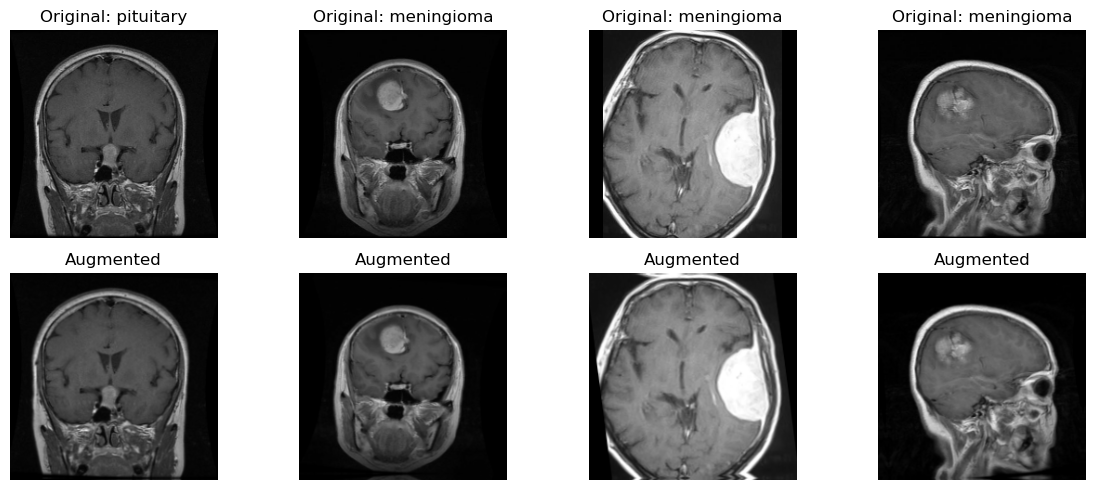

In [42]:

import matplotlib.pyplot as plt

for images, labels in train_ds.take(1):

    augmented_images = data_augmentation(
        images,
        training=True
    )

    plt.figure(figsize=(12, 5))

    for i in range(4):

        # Original image
        plt.subplot(2, 4, i + 1)
        plt.imshow(images[i].numpy())
        plt.title(f"Original: {CLASSES[int(labels[i])]}")
        plt.axis("off")

        # Augmented image
        plt.subplot(2, 4, i + 5)
        plt.imshow(augmented_images[i].numpy())
        plt.title("Augmented")
        plt.axis("off")

    plt.tight_layout()
    plt.show()


In [43]:
from pathlib import Path

model_files = [
    "best_finetuned_model.keras",
    "best_mobilenet_model.keras",
    "final_brain_tumor_model.keras"
]

for filename in model_files:
    path = PROJECT_PATH / filename
    print(filename, "->", path.exists())

best_finetuned_model.keras -> True
best_mobilenet_model.keras -> True
final_brain_tumor_model.keras -> True


In [44]:

import tensorflow as tf

BEST_MODEL_PATH = PROJECT_PATH / "best_finetuned_model.keras"

experiment_model = tf.keras.models.load_model(
    BEST_MODEL_PATH,
    compile=False
)

print("Model loaded successfully!")
print("Input shape:", experiment_model.input_shape)
print("Output shape:", experiment_model.output_shape)
print("\nModel layers:")

for i, layer in enumerate(experiment_model.layers):
    print(
        i,
        layer.name,
        "| Trainable:", layer.trainable,
        "| Type:", type(layer).__name__
    )


Model loaded successfully!
Input shape: (None, 224, 224, 3)
Output shape: (None, 4)

Model layers:
0 input_layer_3 | Trainable: True | Type: InputLayer
1 sequential | Trainable: True | Type: Sequential
2 rescaling | Trainable: True | Type: Rescaling
3 mobilenetv2_1.00_224 | Trainable: True | Type: Functional
4 global_average_pooling2d_1 | Trainable: True | Type: GlobalAveragePooling2D
5 dropout_1 | Trainable: True | Type: Dropout
6 dense_2 | Trainable: True | Type: Dense
7 dropout_2 | Trainable: True | Type: Dropout
8 dense_3 | Trainable: True | Type: Dense


In [45]:

base_model = experiment_model.get_layer("mobilenetv2_1.00_224")

print("Total MobileNetV2 layers:", len(base_model.layers))
print("Trainable layers:", sum(
    layer.trainable for layer in base_model.layers
))

print("\nLast 25 MobileNetV2 layers:")

for i, layer in enumerate(base_model.layers[-25:]):
    actual_index = len(base_model.layers) - 25 + i
    print(
        actual_index,
        layer.name,
        "| Trainable:", layer.trainable
    )


Total MobileNetV2 layers: 154
Trainable layers: 20

Last 25 MobileNetV2 layers:
129 block_14_depthwise_BN | Trainable: False
130 block_14_depthwise_relu | Trainable: True
131 block_14_project | Trainable: True
132 block_14_project_BN | Trainable: False
133 block_14_add | Trainable: True
134 block_15_expand | Trainable: True
135 block_15_expand_BN | Trainable: False
136 block_15_expand_relu | Trainable: True
137 block_15_depthwise | Trainable: True
138 block_15_depthwise_BN | Trainable: False
139 block_15_depthwise_relu | Trainable: True
140 block_15_project | Trainable: True
141 block_15_project_BN | Trainable: False
142 block_15_add | Trainable: True
143 block_16_expand | Trainable: True
144 block_16_expand_BN | Trainable: False
145 block_16_expand_relu | Trainable: True
146 block_16_depthwise | Trainable: True
147 block_16_depthwise_BN | Trainable: False
148 block_16_depthwise_relu | Trainable: True
149 block_16_project | Trainable: True
150 block_16_project_BN | Trainable: False
151

In [46]:
augmentation_layer = experiment_model.get_layer("sequential")

print("Augmentation configuration:\n")

for layer in augmentation_layer.layers:
    print(layer.name, layer.get_config())

Augmentation configuration:

random_rotation {'name': 'random_rotation', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name': None}, 'data_format': 'channels_last', 'factor': (-0.03, 0.03), 'fill_mode': 'reflect', 'fill_value': 0.0, 'interpolation': 'bilinear', 'seed': None}
random_zoom {'name': 'random_zoom', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name': None}, 'data_format': 'channels_last', 'height_factor': 0.08, 'width_factor': 0.08, 'fill_mode': 'reflect', 'interpolation': 'bilinear', 'seed': None, 'fill_value': 0.0}
random_contrast {'name': 'random_contrast', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name': None}, 'data_format': 'channels_last', 'factor': (0, 0.1), 'value_range': [0, 255], 'seed': None}


In [47]:

# Create corrected augmentation
corrected_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(
        factor=0.03,
        fill_mode="reflect"
    ),
    tf.keras.layers.RandomZoom(
        height_factor=0.08,
        width_factor=0.08,
        fill_mode="reflect"
    ),
    tf.keras.layers.RandomContrast(
        factor=0.1,
        value_range=(0, 1)
    )
], name="corrected_augmentation")

# Reuse the trained layers and weights
inputs = tf.keras.Input(shape=(224, 224, 3))

x = corrected_augmentation(inputs)

x = experiment_model.get_layer("rescaling")(x)

base_model = experiment_model.get_layer(
    "mobilenetv2_1.00_224"
)

x = base_model(x)

x = experiment_model.get_layer(
    "global_average_pooling2d_1"
)(x)

x = experiment_model.get_layer("dropout_1")(x)
x = experiment_model.get_layer("dense_2")(x)
x = experiment_model.get_layer("dropout_2")(x)
outputs = experiment_model.get_layer("dense_3")(x)

corrected_model = tf.keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="corrected_mobilenetv2"
)

print("Corrected model created!")
print("Input:", corrected_model.input_shape)
print("Output:", corrected_model.output_shape)
print("Total parameters:", corrected_model.count_params())

print("\nNew augmentation configuration:")
for layer in corrected_augmentation.layers:
    print(layer.name, layer.get_config())


Corrected model created!
Input: (None, 224, 224, 3)
Output: (None, 4)
Total parameters: 2422468

New augmentation configuration:
random_rotation_3 {'name': 'random_rotation_3', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name': None}, 'data_format': 'channels_last', 'factor': (-0.03, 0.03), 'fill_mode': 'reflect', 'fill_value': 0.0, 'interpolation': 'bilinear', 'seed': None}
random_zoom_3 {'name': 'random_zoom_3', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name': None}, 'data_format': 'channels_last', 'height_factor': 0.08, 'width_factor': 0.08, 'fill_mode': 'reflect', 'interpolation': 'bilinear', 'seed': None, 'fill_value': 0.0}
random_contrast_3 {'name': 'random_contrast_3', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name': None}, 'data_format': 'channels_la

In [48]:

# Configure MobileNetV2 backbone
base_model.trainable = True

# Freeze early layers; fine-tune final 20
for layer in base_model.layers[:-20]:
    layer.trainable = False

for layer in base_model.layers[-20:]:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False
    else:
        layer.trainable = True

print("Total backbone layers:", len(base_model.layers))
print(
    "Trainable backbone layers:",
    sum(layer.trainable for layer in base_model.layers)
)

print("\nTrainable layer names:")
for layer in base_model.layers:
    if layer.trainable:
        print(layer.name)


Total backbone layers: 154
Trainable backbone layers: 13

Trainable layer names:
block_15_expand
block_15_expand_relu
block_15_depthwise
block_15_depthwise_relu
block_15_project
block_15_add
block_16_expand
block_16_expand_relu
block_16_depthwise
block_16_depthwise_relu
block_16_project
Conv_1
out_relu


In [49]:

corrected_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

print("Optimizer:", corrected_model.optimizer.__class__.__name__)
print("Learning rate:", float(
    tf.keras.backend.get_value(
        corrected_model.optimizer.learning_rate
    )
))
print("Loss:", corrected_model.loss)


Model compiled successfully!
Optimizer: Adam
Learning rate: 9.999999747378752e-06
Loss: sparse_categorical_crossentropy


In [50]:

from pathlib import Path

EXPERIMENT_PATH = PROJECT_PATH / "mobilenetv2_corrected_experiment.keras"

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(EXPERIMENT_PATH),
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

history_corrected = corrected_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)


Epoch 1/10


D:\anaconda\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


496/496 ━━━━━━━━━━━━━━━━━━━━ 0s 320ms/step - accuracy: 0.9614 - loss: 0.1100
Epoch 1: val_accuracy improved from None to 0.92331, saving model to C:\Users\Chaithanya Reddy\Projects\Brain_Tumor_AI_Project\mobilenetv2_corrected_experiment.keras

Epoch 1: finished saving model to C:\Users\Chaithanya Reddy\Projects\Brain_Tumor_AI_Project\mobilenetv2_corrected_experiment.keras
496/496 ━━━━━━━━━━━━━━━━━━━━ 217s 393ms/step - accuracy: 0.9614 - loss: 0.1100 - val_accuracy: 0.9233 - val_loss: 0.2105 - learning_rate: 1.0000e-05
Epoch 2/10
496/496 ━━━━━━━━━━━━━━━━━━━━ 0s 272ms/step - accuracy: 0.9604 - loss: 0.1086
Epoch 2: val_accuracy did not improve from 0.92331
496/496 ━━━━━━━━━━━━━━━━━━━━ 156s 313ms/step - accuracy: 0.9604 - loss: 0.1086 - val_accuracy: 0.9162 - val_loss: 0.2347 - learning_rate: 1.0000e-05
Epoch 3/10
496/496 ━━━━━━━━━━━━━━━━━━━━ 0s 192ms/step - accuracy: 0.9677 - loss: 0.0917
Epoch 3: val_accuracy did not improve from 0.92331

Epoch 3: ReduceLROnPlateau reducing learning rat

In [51]:

# Load the best saved checkpoint
corrected_best_model = tf.keras.models.load_model(
    EXPERIMENT_PATH,
    compile=False
)

# Compile for evaluation
corrected_best_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Validation evaluation
val_loss, val_accuracy = corrected_best_model.evaluate(
    val_ds,
    verbose=1
)

print("\nCorrected MobileNetV2 Validation Results")
print("Validation Accuracy:", round(val_accuracy * 100, 2), "%")
print("Validation Loss:", round(val_loss, 4))


124/124 ━━━━━━━━━━━━━━━━━━━━ 50s 325ms/step - accuracy: 0.9233 - loss: 0.2105

Corrected MobileNetV2 Validation Results
Validation Accuracy: 92.33 %
Validation Loss: 0.2105


In [53]:

import pandas as pd
from pathlib import Path
import tensorflow as tf

PROJECT_PATH = Path(
    r"C:\Users\Chaithanya Reddy\Projects\Brain_Tumor_AI_Project"
)

OUTPUT_PATH = PROJECT_PATH / "processed_data"

# Reload test manifest
test_manifest = pd.read_csv(
    OUTPUT_PATH / "test_manifest.csv"
)

print("Test manifest loaded!")
print("Test images:", len(test_manifest))
print("Columns:", test_manifest.columns.tolist())

print(
    "All test paths exist:",
    test_manifest["filepath"].apply(
        lambda p: Path(p).exists()
    ).all()
)


Test manifest loaded!
Test images: 1000
Columns: ['relative_path', 'filename', 'task', 'split', 'index', 'tumor_code', 'tumor_label', 'plane_code', 'plane_label', 'sequence', 'is_mask', 'linked_image', 'width', 'height', 'file_size_bytes', 'sha256', 'dimensions', 'filepath']
All test paths exist: True


In [54]:

import numpy as np
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

# Prepare test paths and labels
test_paths, test_labels = prepare_dataframe(test_manifest)

# Confirm test files exist
assert all(Path(p).exists() for p in test_paths), \
    "Some test image paths are missing!"

# Use the same preprocessing as training
test_ds_corrected = (
    tf.data.Dataset.from_tensor_slices(
        (test_paths, test_labels)
    )
    .map(preprocess_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

# Evaluate model
test_loss, test_accuracy = corrected_best_model.evaluate(
    test_ds_corrected,
    verbose=1
)

# Predictions
probabilities = corrected_best_model.predict(
    test_ds_corrected,
    verbose=1
)

y_pred = np.argmax(probabilities, axis=1)
y_true = test_labels

print("\nFINAL TEST RESULTS")
print("Test images:", len(y_true))
print("Correct predictions:", int(np.sum(y_true == y_pred)))
print("Test accuracy:", round(accuracy_score(y_true, y_pred) * 100, 2), "%")
print("Test loss:", round(test_loss, 4))

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_true,
    y_pred,
    target_names=CLASSES,
    digits=4
))

print("\nCONFUSION MATRIX")
print(confusion_matrix(y_true, y_pred))


125/125 ━━━━━━━━━━━━━━━━━━━━ 34s 266ms/step - accuracy: 0.9250 - loss: 0.2097
125/125 ━━━━━━━━━━━━━━━━━━━━ 36s 255ms/step

FINAL TEST RESULTS
Test images: 1000
Correct predictions: 925
Test accuracy: 92.5 %
Test loss: 0.2097

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      glioma     0.9633    0.8268    0.8898       254
  meningioma     0.8607    0.9085    0.8839       306
    no_tumor     0.9789    0.9929    0.9858       140
   pituitary     0.9401    0.9933    0.9660       300

    accuracy                         0.9250      1000
   macro avg     0.9357    0.9304    0.9314      1000
weighted avg     0.9271    0.9250    0.9243      1000


CONFUSION MATRIX
[[210  43   0   1]
 [  7 278   3  18]
 [  0   1 139   0]
 [  1   1   0 298]]


In [55]:

import json
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

RESULTS_PATH = PROJECT_PATH / "results"
RESULTS_PATH.mkdir(exist_ok=True)

report = classification_report(
    y_true,
    y_pred,
    target_names=CLASSES,
    output_dict=True,
    zero_division=0
)

summary = {
    "model": "MobileNetV2_Corrected_Augmentation",
    "test_images": int(len(y_true)),
    "correct_predictions": int(np.sum(y_true == y_pred)),
    "test_accuracy": float(test_accuracy),
    "test_loss": float(test_loss),
    "macro_f1": float(report["macro avg"]["f1-score"]),
    "weighted_f1": float(report["weighted avg"]["f1-score"])
}

with open(RESULTS_PATH / "mobilenetv2_corrected_summary.json", "w") as f:
    json.dump(summary, f, indent=4)

with open(RESULTS_PATH / "mobilenetv2_corrected_classification_report.json", "w") as f:
    json.dump(report, f, indent=4)

np.savetxt(
    RESULTS_PATH / "mobilenetv2_corrected_confusion_matrix.csv",
    confusion_matrix(y_true, y_pred),
    delimiter=",",
    fmt="%d"
)

print("Experiment results saved successfully!")
print(summary)


Experiment results saved successfully!
{'model': 'MobileNetV2_Corrected_Augmentation', 'test_images': 1000, 'correct_predictions': 925, 'test_accuracy': 0.925000011920929, 'test_loss': 0.20967289805412292, 'macro_f1': 0.9313883053013045, 'weighted_f1': 0.9243069231156085}


In [56]:

import tensorflow as tf
import pandas as pd
from pathlib import Path

# Configuration
IMG_SIZE = 224
BATCH_SIZE = 8
AUTOTUNE = tf.data.AUTOTUNE

CLASSES = ["glioma", "meningioma", "no_tumor", "pituitary"]
class_to_index = {name: i for i, name in enumerate(CLASSES)}

# Load the existing, identical data splits
train_split = pd.read_csv(OUTPUT_PATH / "train_split.csv")
val_split = pd.read_csv(OUTPUT_PATH / "validation_split.csv")
test_manifest = pd.read_csv(OUTPUT_PATH / "test_manifest.csv")

def get_paths_labels(df):
    paths = df["filepath"].astype(str).values
    labels = df["tumor_label"].map(class_to_index).astype("int32").values
    return paths, labels

eff_train_paths, eff_train_labels = get_paths_labels(train_split)
eff_val_paths, eff_val_labels = get_paths_labels(val_split)
eff_test_paths, eff_test_labels = get_paths_labels(test_manifest)

# EfficientNetB0 input: retain pixel range 0–255
def efficientnet_preprocess(filepath, label):
    image = tf.io.read_file(filepath)
    image = tf.io.decode_jpeg(image, channels=3)
    image = tf.image.resize_with_pad(image, IMG_SIZE, IMG_SIZE)
    image = tf.cast(image, tf.float32)
    return image, label

# Build datasets
eff_train_ds = (
    tf.data.Dataset.from_tensor_slices(
        (eff_train_paths, eff_train_labels)
    )
    .shuffle(1000, seed=42)
    .map(efficientnet_preprocess, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

eff_val_ds = (
    tf.data.Dataset.from_tensor_slices(
        (eff_val_paths, eff_val_labels)
    )
    .map(efficientnet_preprocess, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

eff_test_ds = (
    tf.data.Dataset.from_tensor_slices(
        (eff_test_paths, eff_test_labels)
    )
    .map(efficientnet_preprocess, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

# Verify one batch
for images, labels in eff_train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Pixel minimum:", float(tf.reduce_min(images)))
    print("Pixel maximum:", float(tf.reduce_max(images)))

print("\nEfficientNetB0 datasets ready!")
print("Training:", len(eff_train_paths))
print("Validation:", len(eff_val_paths))
print("Testing:", len(eff_test_paths))
print("Classes:", CLASSES)


Image batch shape: (8, 224, 224, 3)
Label batch shape: (8,)
Pixel minimum: 0.0
Pixel maximum: 250.748779296875

EfficientNetB0 datasets ready!
Training: 3964
Validation: 991
Testing: 1000
Classes: ['glioma', 'meningioma', 'no_tumor', 'pituitary']


In [57]:

# EfficientNetB0 data augmentation
eff_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(
        0.03,
        fill_mode="reflect"
    ),
    tf.keras.layers.RandomZoom(
        0.08,
        fill_mode="reflect"
    ),
    tf.keras.layers.RandomContrast(
        0.1,
        value_range=(0, 255)
    )
], name="efficientnet_augmentation")

# Pretrained EfficientNetB0 backbone
eff_base = tf.keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

# Freeze backbone for initial training
eff_base.trainable = False

# Build classification model
inputs = tf.keras.Input(shape=(224, 224, 3))

x = eff_augmentation(inputs)
x = eff_base(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)
x = tf.keras.layers.Dense(
    128,
    activation="relu"
)(x)
x = tf.keras.layers.Dropout(0.2)(x)

outputs = tf.keras.layers.Dense(
    4,
    activation="softmax"
)(x)

efficientnet_model = tf.keras.Model(
    inputs,
    outputs,
    name="EfficientNetB0_BrainTumor"
)

print("EfficientNetB0 model created!")
print("Input shape:", efficientnet_model.input_shape)
print("Output shape:", efficientnet_model.output_shape)
print("Total parameters:", efficientnet_model.count_params())
print(
    "Trainable parameters:",
    sum(
        int(tf.size(v))
        for v in efficientnet_model.trainable_weights
    )
)


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
EfficientNetB0 model created!
Input shape: (None, 224, 224, 3)
Output shape: (None, 4)
Total parameters: 4214055
Trainable parameters: 164484


In [58]:

from pathlib import Path

EFF_MODEL_PATH = PROJECT_PATH / "efficientnetb0_best.keras"

efficientnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

eff_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(EFF_MODEL_PATH),
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

eff_history = efficientnet_model.fit(
    eff_train_ds,
    validation_data=eff_val_ds,
    epochs=8,
    callbacks=eff_callbacks
)


Epoch 1/8


D:\anaconda\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


496/496 ━━━━━━━━━━━━━━━━━━━━ 0s 398ms/step - accuracy: 0.7800 - loss: 0.5591
Epoch 1: val_accuracy improved from None to 0.83148, saving model to C:\Users\Chaithanya Reddy\Projects\Brain_Tumor_AI_Project\efficientnetb0_best.keras

Epoch 1: finished saving model to C:\Users\Chaithanya Reddy\Projects\Brain_Tumor_AI_Project\efficientnetb0_best.keras
496/496 ━━━━━━━━━━━━━━━━━━━━ 293s 520ms/step - accuracy: 0.7800 - loss: 0.5591 - val_accuracy: 0.8315 - val_loss: 0.4517 - learning_rate: 0.0010
Epoch 2/8
496/496 ━━━━━━━━━━━━━━━━━━━━ 0s 378ms/step - accuracy: 0.8469 - loss: 0.3906
Epoch 2: val_accuracy improved from 0.83148 to 0.84662, saving model to C:\Users\Chaithanya Reddy\Projects\Brain_Tumor_AI_Project\efficientnetb0_best.keras

Epoch 2: finished saving model to C:\Users\Chaithanya Reddy\Projects\Brain_Tumor_AI_Project\efficientnetb0_best.keras
496/496 ━━━━━━━━━━━━━━━━━━━━ 231s 466ms/step - accuracy: 0.8469 - loss: 0.3906 - val_accuracy: 0.8466 - val_loss: 0.4096 - learning_rate: 0.0010

In [59]:

# Load the best Stage 1 checkpoint (epoch 8)
efficientnet_model = tf.keras.models.load_model(
    PROJECT_PATH / "efficientnetb0_best.keras"
)

# Get EfficientNetB0 backbone
eff_base = efficientnet_model.get_layer("efficientnetb0")

# Enable fine-tuning
eff_base.trainable = True

# Freeze earlier layers; unfreeze final 30
for layer in eff_base.layers[:-30]:
    layer.trainable = False

# Keep all BatchNormalization layers frozen
for layer in eff_base.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

print("Total backbone layers:", len(eff_base.layers))
print(
    "Trainable backbone layers:",
    sum(layer.trainable for layer in eff_base.layers)
)

# Compile with a very low learning rate
efficientnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Fine-tuning callbacks: both monitor validation loss
fine_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(
            PROJECT_PATH / "efficientnetb0_finetuned_best.keras"
        ),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

# Fine-tune
eff_finetune_history = efficientnet_model.fit(
    eff_train_ds,
    validation_data=eff_val_ds,
    epochs=8,
    callbacks=fine_callbacks
)


Total backbone layers: 238
Trainable backbone layers: 23
Epoch 1/8
496/496 ━━━━━━━━━━━━━━━━━━━━ 0s 482ms/step - accuracy: 0.9228 - loss: 0.2025
Epoch 1: val_loss improved from None to 0.27658, saving model to C:\Users\Chaithanya Reddy\Projects\Brain_Tumor_AI_Project\efficientnetb0_finetuned_best.keras

Epoch 1: finished saving model to C:\Users\Chaithanya Reddy\Projects\Brain_Tumor_AI_Project\efficientnetb0_finetuned_best.keras
496/496 ━━━━━━━━━━━━━━━━━━━━ 334s 589ms/step - accuracy: 0.9228 - loss: 0.2025 - val_accuracy: 0.8850 - val_loss: 0.2766 - learning_rate: 1.0000e-05
Epoch 2/8
496/496 ━━━━━━━━━━━━━━━━━━━━ 0s 386ms/step - accuracy: 0.9281 - loss: 0.1853
Epoch 2: val_loss improved from 0.27658 to 0.25774, saving model to C:\Users\Chaithanya Reddy\Projects\Brain_Tumor_AI_Project\efficientnetb0_finetuned_best.keras

Epoch 2: finished saving model to C:\Users\Chaithanya Reddy\Projects\Brain_Tumor_AI_Project\efficientnetb0_finetuned_best.keras
496/496 ━━━━━━━━━━━━━━━━━━━━ 220s 443ms/s

In [60]:

import numpy as np
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

# Load the best fine-tuned model
eff_best_model = tf.keras.models.load_model(
    PROJECT_PATH / "efficientnetb0_finetuned_best.keras"
)

# Predict validation images
val_probabilities = eff_best_model.predict(
    eff_val_ds,
    verbose=1
)

val_predictions = np.argmax(val_probabilities, axis=1)

# Actual labels
val_true = np.concatenate([
    labels.numpy()
    for images, labels in eff_val_ds
])

print("Validation Accuracy:",
      round(accuracy_score(val_true, val_predictions) * 100, 2),
      "%")

print("\nCLASSIFICATION REPORT\n")

print(classification_report(
    val_true,
    val_predictions,
    target_names=CLASSES,
    digits=4
))

print("\nCONFUSION MATRIX\n")

print(confusion_matrix(
    val_true,
    val_predictions
))


124/124 ━━━━━━━━━━━━━━━━━━━━ 32s 230ms/step
Validation Accuracy: 91.02 %

CLASSIFICATION REPORT

              precision    recall  f1-score   support

      glioma     0.9202    0.8559    0.8869       229
  meningioma     0.8669    0.8206    0.8431       262
    no_tumor     1.0000    0.9623    0.9808       212
   pituitary     0.8804    0.9965    0.9349       288

    accuracy                         0.9102       991
   macro avg     0.9169    0.9088    0.9114       991
weighted avg     0.9116    0.9102    0.9093       991


CONFUSION MATRIX

[[196  26   0   7]
 [ 17 215   0  30]
 [  0   6 204   2]
 [  0   1   0 287]]


In [61]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import numpy as np
import json

# Predict on the untouched test set
test_probabilities = eff_best_model.predict(
    eff_test_ds,
    verbose=1
)

test_predictions = np.argmax(test_probabilities, axis=1)

test_true = np.concatenate([
    labels.numpy()
    for images, labels in eff_test_ds
])

test_accuracy = accuracy_score(
    test_true,
    test_predictions
)

test_report = classification_report(
    test_true,
    test_predictions,
    target_names=CLASSES,
    output_dict=True,
    digits=4
)

test_cm = confusion_matrix(
    test_true,
    test_predictions
)

print(f"EfficientNetB0 Test Accuracy: {test_accuracy * 100:.2f}%")
print("\nTEST CLASSIFICATION REPORT\n")
print(classification_report(
    test_true,
    test_predictions,
    target_names=CLASSES,
    digits=4
))
print("\nTEST CONFUSION MATRIX\n")
print(test_cm)

# Save final test metrics
results_dir = PROJECT_PATH / "results"
results_dir.mkdir(exist_ok=True)

with open(results_dir / "efficientnetb0_test_report.json", "w") as f:
    json.dump(test_report, f, indent=4)

np.savetxt(
    results_dir / "efficientnetb0_test_confusion_matrix.csv",
    test_cm,
    delimiter=",",
    fmt="%d"
)

print("\nTest results saved successfully!")


125/125 ━━━━━━━━━━━━━━━━━━━━ 27s 217ms/step
EfficientNetB0 Test Accuracy: 90.80%

TEST CLASSIFICATION REPORT

              precision    recall  f1-score   support

      glioma     0.9258    0.8346    0.8778       254
  meningioma     0.8828    0.8366    0.8591       306
    no_tumor     0.9929    1.0000    0.9964       140
   pituitary     0.8824    1.0000    0.9375       300

    accuracy                         0.9080      1000
   macro avg     0.9209    0.9178    0.9177      1000
weighted avg     0.9090    0.9080    0.9066      1000


TEST CONFUSION MATRIX

[[212  34   0   8]
 [ 17 256   1  32]
 [  0   0 140   0]
 [  0   0   0 300]]

Test results saved successfully!


In [62]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

# Load our best MobileNetV2 model
mobilenet_model = tf.keras.models.load_model(
    PROJECT_PATH / "mobilenetv2_corrected_experiment.keras"
)

# Access the MobileNetV2 backbone
mobilenet_base = mobilenet_model.get_layer(
    "mobilenetv2_1.00_224"
)

# Identify the final convolutional feature layer
last_conv_layer = mobilenet_base.get_layer("out_relu")

print("Model loaded successfully!")
print("Model:", mobilenet_model.name)
print("Backbone:", mobilenet_base.name)
print("Grad-CAM layer:", last_conv_layer.name)
print("Feature map output shape:", last_conv_layer.output.shape)


Model loaded successfully!
Model: corrected_mobilenetv2
Backbone: mobilenetv2_1.00_224
Grad-CAM layer: out_relu
Feature map output shape: (None, 7, 7, 1280)


In [64]:

def generate_gradcam(model, image, last_conv_layer_name):
    """
    Generate a Grad-CAM heatmap for one MRI image.
    Image shape: (224, 224, 3)
    """

    backbone = model.get_layer("mobilenetv2_1.00_224")
    last_conv_layer = backbone.get_layer(last_conv_layer_name)

    # Create a model that returns feature maps and predictions
    grad_model = tf.keras.Model(
        inputs=model.inputs,
        outputs=[
            last_conv_layer.output,
            model.output
        ]
    )

    image_batch = tf.expand_dims(image, axis=0)

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(
            image_batch,
            training=False
        )

        predicted_class = tf.argmax(
            predictions[0]
        )

        class_score = predictions[:, predicted_class]

    # Calculate gradients
    gradients = tape.gradient(
        class_score,
        conv_outputs
    )

    # Average gradients across spatial dimensions
    pooled_gradients = tf.reduce_mean(
        gradients,
        axis=(0, 1, 2)
    )

    # Weight feature maps using gradients
    conv_outputs = conv_outputs[0]

    heatmap = tf.reduce_sum(
        conv_outputs * pooled_gradients,
        axis=-1
    )

    # Keep positive contributions
    heatmap = tf.maximum(heatmap, 0)

    # Normalize heatmap
    heatmap = heatmap / (
        tf.reduce_max(heatmap) + tf.keras.backend.epsilon()
    )

    # Resize to original MRI dimensions
    heatmap = tf.image.resize(
        heatmap[..., tf.newaxis],
        (224, 224)
    )

    return heatmap.numpy().squeeze(), predictions.numpy()[0]


In [66]:
def generate_gradcam(model, image, last_conv_layer_name):

    # Get the MobileNetV2 backbone
    backbone = model.get_layer("mobilenetv2_1.00_224")

    # Get the final convolutional layer
    last_conv_layer = backbone.get_layer(last_conv_layer_name)

    # Create a model connected directly to the backbone input
    base_grad_model = tf.keras.Model(
        inputs=backbone.input,
        outputs=[
            last_conv_layer.output,
            backbone.output
        ]
    )

    # Get preprocessing and classification layers
    augmentation = model.get_layer("corrected_augmentation")
    rescaling = model.get_layer("rescaling")

    gap = model.get_layer("global_average_pooling2d_1")
    dropout1 = model.get_layer("dropout_1")
    dense1 = model.get_layer("dense_2")
    dropout2 = model.get_layer("dropout_2")
    classifier = model.get_layer("dense_3")

    image_batch = tf.expand_dims(image, axis=0)

    with tf.GradientTape() as tape:

        # Apply the same preprocessing as the original model
        x = augmentation(image_batch, training=False)
        x = rescaling(x)

        # Extract convolutional features
        conv_outputs, backbone_output = base_grad_model(
            x, training=False
        )

        # Pass features through the original classification head
        x = gap(backbone_output)
        x = dropout1(x, training=False)
        x = dense1(x)
        x = dropout2(x, training=False)
        predictions = classifier(x)

        predicted_class = tf.argmax(predictions[0])
        class_score = predictions[:, predicted_class]

    # Calculate gradients
    gradients = tape.gradient(class_score, conv_outputs)

    # Calculate channel importance
    pooled_gradients = tf.reduce_mean(
        gradients, axis=(0, 1, 2)
    )

    conv_outputs = conv_outputs[0]

    # Generate heatmap
    heatmap = tf.reduce_sum(
        conv_outputs * pooled_gradients,
        axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)

    heatmap = heatmap / (
        tf.reduce_max(heatmap) + tf.keras.backend.epsilon()
    )

    heatmap = tf.image.resize(
        heatmap[..., tf.newaxis],
        (224, 224)
    )

    return heatmap.numpy().squeeze(), predictions.numpy()[0]

In [67]:
heatmap, probabilities = generate_gradcam(
    mobilenet_model,
    sample_image,
    "out_relu"
)

predicted_index = np.argmax(probabilities)

print("Actual class:", sample_row["tumor_label"])
print("Predicted class:", CLASSES[predicted_index])
print("Confidence:", round(float(probabilities[predicted_index]) * 100, 2), "%")
print("Heatmap shape:", heatmap.shape)
print("Heatmap range:", heatmap.min(), "to", heatmap.max())

Actual class: glioma
Predicted class: glioma
Confidence: 99.76 %
Heatmap shape: (224, 224)
Heatmap range: 0.0 to 0.9918998


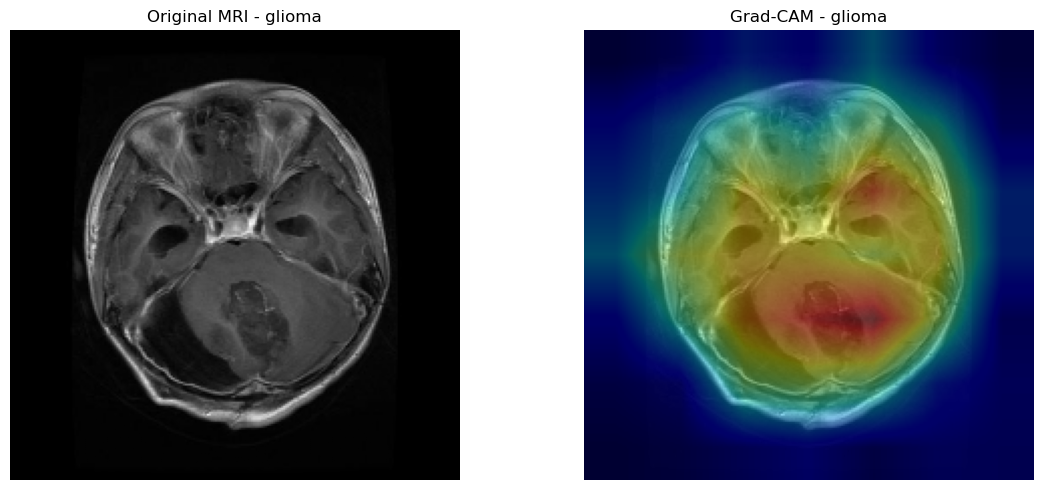

In [68]:
import matplotlib.pyplot as plt
import numpy as np

# Convert tensors to NumPy arrays
original_image = sample_image.numpy()
heatmap_image = np.uint8(255 * heatmap)

# Display both images
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.title("Original MRI - " + sample_row["tumor_label"])
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(original_image)
plt.imshow(
    heatmap_image,
    cmap="jet",
    alpha=0.4,
    vmin=0,
    vmax=255
)
plt.title("Grad-CAM - " + CLASSES[predicted_index])
plt.axis("off")

plt.tight_layout()
plt.show()

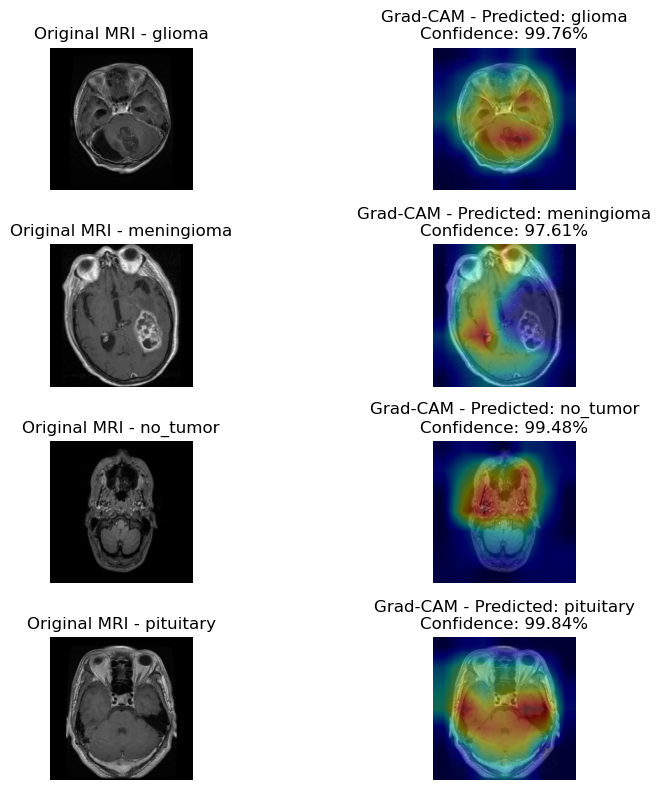

Grad-CAM images saved to: C:\Users\Chaithanya Reddy\Projects\Brain_Tumor_AI_Project\results\gradcam


In [70]:
from pathlib import Path
import matplotlib.pyplot as plt
import tensorflow as tf
import numpy as np

# Create output folder
gradcam_dir = OUTPUT_PATH.parent / "results" / "gradcam"
gradcam_dir.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(4, 2, figsize=(10, 8))

for i, class_name in enumerate(CLASSES):

    # Select one test image from this class
    sample_row = test_manifest[
        test_manifest["tumor_label"] == class_name
    ].iloc[0]

    # Load and preprocess image
    image_bytes = tf.io.read_file(sample_row["filepath"])
    image = tf.io.decode_image(
        image_bytes, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])

    image = tf.image.resize_with_pad(image, 224, 224)
    image = tf.cast(image, tf.float32) / 255.0

    # Generate Grad-CAM
    heatmap, probabilities = generate_gradcam(
        mobilenet_model, image, "out_relu"
    )

    predicted_index = np.argmax(probabilities)
    confidence = probabilities[predicted_index] * 100

    # Original image
    axes[i, 0].imshow(image.numpy())
    axes[i, 0].set_title(f"Original MRI - {class_name}")
    axes[i, 0].axis("off")

    # Grad-CAM overlay
    axes[i, 1].imshow(image.numpy())
    axes[i, 1].imshow(
        heatmap, cmap="jet", alpha=0.4, vmin=0, vmax=1
    )
    axes[i, 1].set_title(
        f"Grad-CAM - Predicted: {CLASSES[predicted_index]}\n"
        f"Confidence: {confidence:.2f}%"
    )
    axes[i, 1].axis("off")

    # Save individual visualization
    individual_fig, individual_axes = plt.subplots(1, 2, figsize=(10, 5))

    individual_axes[0].imshow(image.numpy())
    individual_axes[0].set_title(f"Original MRI - {class_name}")
    individual_axes[0].axis("off")

    individual_axes[1].imshow(image.numpy())
    individual_axes[1].imshow(
        heatmap, cmap="jet", alpha=0.4, vmin=0, vmax=1
    )
    individual_axes[1].set_title(
        f"Grad-CAM - {CLASSES[predicted_index]} ({confidence:.2f}%)"
    )
    individual_axes[1].axis("off")

    individual_fig.tight_layout()
    individual_fig.savefig(
        gradcam_dir / f"gradcam_{class_name}.png",
        dpi=200,
        bbox_inches="tight"
    )
    plt.close(individual_fig)

plt.tight_layout()
plt.savefig(
    gradcam_dir / "all_classes_gradcam.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print("Grad-CAM images saved to:", gradcam_dir)

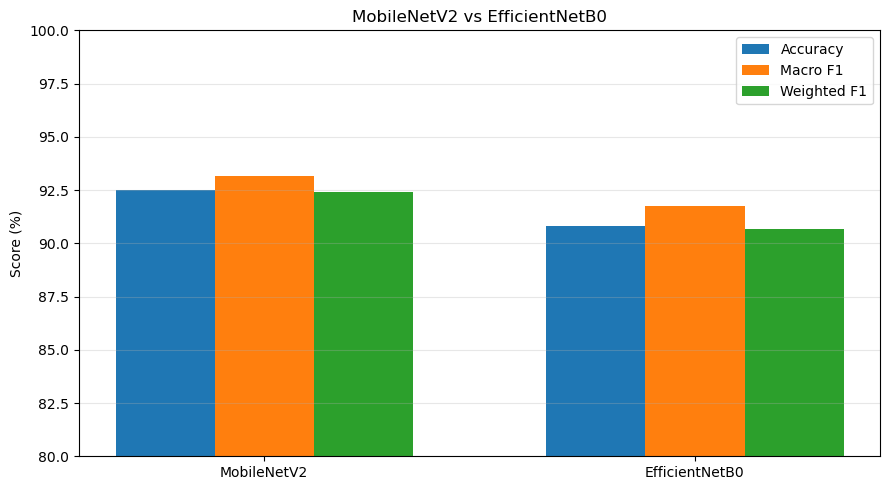

In [71]:
import matplotlib.pyplot as plt
import numpy as np

models = ["MobileNetV2", "EfficientNetB0"]

accuracy = [92.50, 90.80]
macro_f1 = [93.14, 91.77]
weighted_f1 = [92.43, 90.66]

x = np.arange(len(models))
width = 0.23

plt.figure(figsize=(9, 5))

plt.bar(x - width, accuracy, width, label="Accuracy")
plt.bar(x, macro_f1, width, label="Macro F1")
plt.bar(x + width, weighted_f1, width, label="Weighted F1")

plt.xticks(x, models)
plt.ylabel("Score (%)")
plt.ylim(80, 100)
plt.title("MobileNetV2 vs EfficientNetB0")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    PROJECT_PATH / "results" / "model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [72]:
import json
from pathlib import Path

results_dir = PROJECT_PATH / "results"
results_dir.mkdir(parents=True, exist_ok=True)

final_results = {
    "project": "AI-Based Brain Tumor Classification Using MRI",
    "dataset": "BRISC 2025",
    "classes": CLASSES,
    "primary_model": {
        "name": "MobileNetV2",
        "test_accuracy": 92.50,
        "macro_precision": 93.57,
        "macro_recall": 93.04,
        "macro_f1": 93.14,
        "weighted_f1": 92.43
    },
    "comparison_model": {
        "name": "EfficientNetB0",
        "test_accuracy": 90.80,
        "macro_precision": 92.09,
        "macro_recall": 91.78,
        "macro_f1": 91.77,
        "weighted_f1": 90.66
    },
    "explainability": "Grad-CAM",
    "test_images": 1000
}

with open(results_dir / "final_project_results.json", "w") as file:
    json.dump(final_results, file, indent=4)

print("Final results saved successfully!")
print("Location:", results_dir / "final_project_results.json")

Final results saved successfully!
Location: C:\Users\Chaithanya Reddy\Projects\Brain_Tumor_AI_Project\results\final_project_results.json


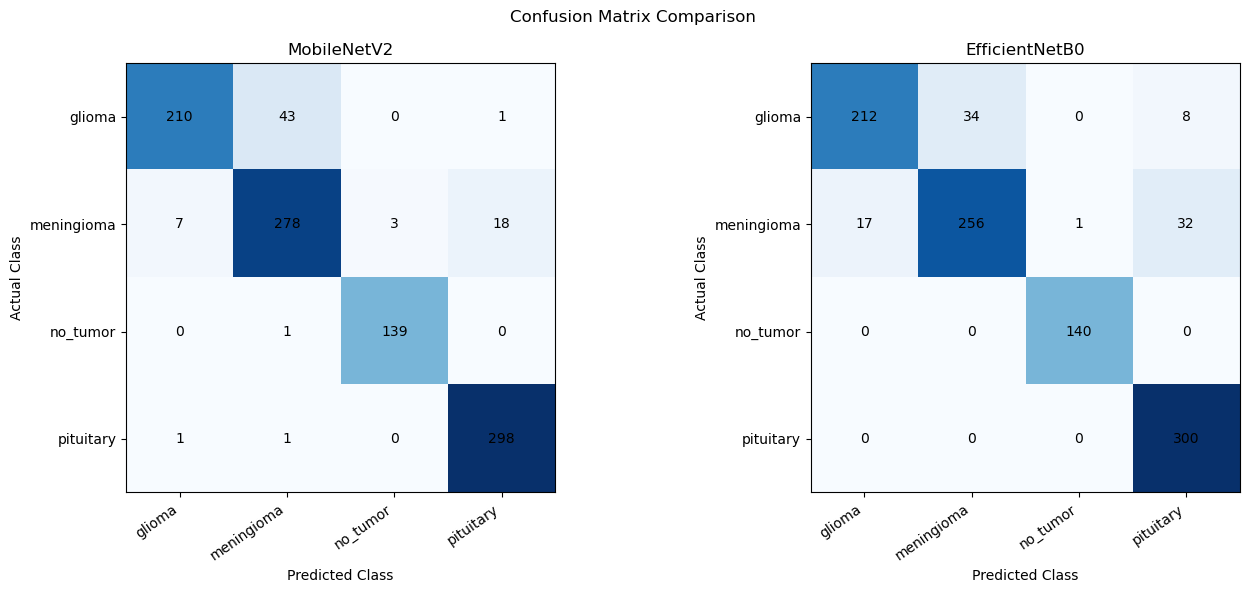

In [73]:
import matplotlib.pyplot as plt
import numpy as np

# Confusion matrices: rows = actual, columns = predicted
mobilenet_cm = np.array([
    [210, 43, 0, 1],
    [7, 278, 3, 18],
    [0, 1, 139, 0],
    [1, 1, 0, 298]
])

efficientnet_cm = np.array([
    [212, 34, 0, 8],
    [17, 256, 1, 32],
    [0, 0, 140, 0],
    [0, 0, 0, 300]
])

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

matrices = [
    (mobilenet_cm, "MobileNetV2"),
    (efficientnet_cm, "EfficientNetB0")
]

for ax, (cm, title) in zip(axes, matrices):

    ax.imshow(cm, cmap="Blues")

    ax.set_title(title)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

    ax.set_xticks(range(4))
    ax.set_yticks(range(4))
    ax.set_xticklabels(CLASSES, rotation=35, ha="right")
    ax.set_yticklabels(CLASSES)

    for i in range(4):
        for j in range(4):
            ax.text(
                j, i, str(cm[i, j]),
                ha="center",
                va="center",
                color="black"
            )

plt.suptitle("Confusion Matrix Comparison")
plt.tight_layout()

plt.savefig(
    PROJECT_PATH / "results" / "confusion_matrix_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [74]:
pip install streamlit pillow

  Attempting uninstall: protobuf
    Found existing installation: protobuf 7.36.2
    Uninstalling protobuf-7.36.2:
      Successfully uninstalled protobuf-7.36.2
Note: you may need to restart the kernel to use updated packages.


  You can safely remove it manually.


In [76]:
%%writefile app.py

import streamlit as st
import tensorflow as tf
import numpy as np
from PIL import Image
from pathlib import Path

# Project configuration
PROJECT_PATH = Path(__file__).resolve().parent

MODEL_PATH = PROJECT_PATH / "mobilenetv2_corrected_experiment.keras"

CLASSES = [
    "glioma",
    "meningioma",
    "no_tumor",
    "pituitary"
]
st.set_page_config(
    page_title="Brain Tumor Classification",
    page_icon="🧠",
    layout="wide"
)
# Load trained model
@st.cache_resource
def load_model():
    return tf.keras.models.load_model(MODEL_PATH)

model = load_model()

# Page configuration


st.title("🧠 AI-Based Brain Tumor Classification")
st.write("MRI Image Analysis using MobileNetV2 and Explainable AI")

st.info(
    "Upload a brain MRI image to obtain an experimental "
    "four-class model prediction."
)

# Upload MRI
uploaded_file = st.file_uploader(
    "Upload Brain MRI Image",
    type=["jpg", "jpeg", "png"]
)

if uploaded_file is not None:

    image = Image.open(uploaded_file).convert("RGB")

    col1, col2 = st.columns(2)

    with col1:
        st.subheader("Uploaded MRI")
        st.image(image, use_container_width=True)

    if st.button("Analyze MRI", type="primary"):

        with st.spinner("Analyzing image..."):

            image_array = np.array(image)

            image_tensor = tf.convert_to_tensor(
                image_array,
                dtype=tf.float32
            )

            image_tensor = tf.image.resize_with_pad(
                image_tensor,
                224,
                224
            )

            image_tensor = image_tensor / 255.0

            image_tensor = tf.expand_dims(
                image_tensor,
                axis=0
            )

            predictions = model.predict(
                image_tensor,
                verbose=0
            )[0]

            predicted_index = np.argmax(predictions)
            predicted_class = CLASSES[predicted_index]
            confidence = predictions[predicted_index] * 100

        with col2:
            st.subheader("Prediction Result")
            st.success(f"Predicted Class: {predicted_class}")
            st.metric("Model Confidence", f"{confidence:.2f}%")

        st.subheader("Class Probabilities")

        for class_name, probability in zip(CLASSES, predictions):
            st.write(
                f"{class_name}: {probability * 100:.2f}%"
            )
            st.progress(float(probability))

st.divider()

st.warning(
    "Research and educational prototype only. "
    "This model is not a medical diagnostic tool. "
    "Do not use its predictions for clinical decisions."
)

Overwriting app.py


In [80]:
import sys
import tensorflow as tf

print("Python executable:", sys.executable)
print("TensorFlow version:", tf.__version__)

Python executable: D:\anaconda\python.exe
TensorFlow version: 2.21.0


In [81]:
import tensorflow as tf

MODEL_PATH = PROJECT_PATH / "mobilenetv2_corrected_experiment.keras"

gradcam_model = tf.keras.models.load_model(MODEL_PATH)

print("Model loaded successfully!")

print("\nMain model layers:")
for layer in gradcam_model.layers:
    print(layer.name)

print("\nMobileNetV2 final convolution layer:")
backbone = gradcam_model.get_layer("mobilenetv2_1.00_224")
print(backbone.get_layer("out_relu").name)

Model loaded successfully!

Main model layers:
input_layer_1
corrected_augmentation
rescaling
mobilenetv2_1.00_224
global_average_pooling2d_1
dropout_1
dense_2
dropout_2
dense_3

MobileNetV2 final convolution layer:
out_relu


In [82]:
import tensorflow as tf
import numpy as np

def generate_gradcam(model, image):
    backbone = model.get_layer("mobilenetv2_1.00_224")
    last_conv_layer = backbone.get_layer("out_relu")

    base_grad_model = tf.keras.Model(
        inputs=backbone.input,
        outputs=[last_conv_layer.output, backbone.output]
    )

    augmentation = model.get_layer("corrected_augmentation")
    rescaling = model.get_layer("rescaling")
    gap = model.get_layer("global_average_pooling2d_1")
    dropout1 = model.get_layer("dropout_1")
    dense1 = model.get_layer("dense_2")
    dropout2 = model.get_layer("dropout_2")
    classifier = model.get_layer("dense_3")

    image_batch = tf.expand_dims(image, axis=0)

    with tf.GradientTape() as tape:
        x = augmentation(image_batch, training=False)
        x = rescaling(x)

        conv_outputs, backbone_output = base_grad_model(
            x, training=False
        )

        x = gap(backbone_output)
        x = dropout1(x, training=False)
        x = dense1(x)
        x = dropout2(x, training=False)
        predictions = classifier(x)

        predicted_class = tf.argmax(predictions[0])
        class_score = predictions[:, predicted_class]

    gradients = tape.gradient(class_score, conv_outputs)

    pooled_gradients = tf.reduce_mean(
        gradients, axis=(0, 1, 2)
    )

    conv_outputs = conv_outputs[0]

    heatmap = tf.reduce_sum(
        conv_outputs * pooled_gradients, axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)

    heatmap = heatmap / (
        tf.reduce_max(heatmap) + tf.keras.backend.epsilon()
    )

    heatmap = tf.image.resize(
        heatmap[..., tf.newaxis], (224, 224)
    )

    return heatmap.numpy().squeeze(), predictions.numpy()[0]

print("Grad-CAM function created successfully!")

Grad-CAM function created successfully!


In [83]:

%%writefile app.py

import streamlit as st
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from pathlib import Path

st.set_page_config(
    page_title="Brain Tumor Classification",
    page_icon="🧠",
    layout="wide"
)

PROJECT_PATH = Path(__file__).resolve().parent
MODEL_PATH = PROJECT_PATH / "mobilenetv2_corrected_experiment.keras"

CLASSES = ["glioma", "meningioma", "no_tumor", "pituitary"]

@st.cache_resource
def load_model():
    return tf.keras.models.load_model(MODEL_PATH)

model = load_model()


def preprocess_image(image):
    image_array = np.array(image.convert("RGB"))
    tensor = tf.convert_to_tensor(image_array, dtype=tf.float32)
    tensor = tf.image.resize_with_pad(tensor, 224, 224)
    tensor = tensor / 255.0
    return tensor


def generate_gradcam(model, image):
    backbone = model.get_layer("mobilenetv2_1.00_224")
    last_conv_layer = backbone.get_layer("out_relu")

    grad_model = tf.keras.Model(
        inputs=backbone.input,
        outputs=[last_conv_layer.output, backbone.output]
    )

    augmentation = model.get_layer("corrected_augmentation")
    rescaling = model.get_layer("rescaling")
    gap = model.get_layer("global_average_pooling2d_1")
    dropout1 = model.get_layer("dropout_1")
    dense1 = model.get_layer("dense_2")
    dropout2 = model.get_layer("dropout_2")
    classifier = model.get_layer("dense_3")

    image_batch = tf.expand_dims(image, axis=0)

    with tf.GradientTape() as tape:
        x = augmentation(image_batch, training=False)
        x = rescaling(x)

        conv_outputs, backbone_output = grad_model(
            x, training=False
        )

        x = gap(backbone_output)
        x = dropout1(x, training=False)
        x = dense1(x)
        x = dropout2(x, training=False)
        predictions = classifier(x)

        predicted_class = tf.argmax(predictions[0])
        class_score = predictions[:, predicted_class]

    gradients = tape.gradient(class_score, conv_outputs)

    pooled_gradients = tf.reduce_mean(
        gradients, axis=(0, 1, 2)
    )

    conv_outputs = conv_outputs[0]

    heatmap = tf.reduce_sum(
        conv_outputs * pooled_gradients, axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)

    heatmap = heatmap / (
        tf.reduce_max(heatmap) + tf.keras.backend.epsilon()
    )

    heatmap = tf.image.resize(
        heatmap[..., tf.newaxis], (224, 224)
    )

    return heatmap.numpy().squeeze(), predictions.numpy()[0]


st.title("🧠 AI-Based Brain Tumor Classification")
st.write("MRI Image Analysis using MobileNetV2 and Explainable AI")

st.info(
    "Upload a brain MRI image for experimental four-class "
    "classification and Grad-CAM visualization."
)

uploaded_file = st.file_uploader(
    "Upload Brain MRI Image",
    type=["jpg", "jpeg", "png"]
)

if uploaded_file is not None:

    image = Image.open(uploaded_file).convert("RGB")

    col1, col2 = st.columns(2)

    with col1:
        st.subheader("Uploaded MRI")
        st.image(image, use_container_width=True)

    if st.button("Analyze MRI", type="primary"):

        with st.spinner("Analyzing MRI and generating Grad-CAM..."):

            image_tensor = preprocess_image(image)

            heatmap, predictions = generate_gradcam(
                model, image_tensor
            )

            predicted_index = int(np.argmax(predictions))
            predicted_class = CLASSES[predicted_index]
            confidence = float(predictions[predicted_index]) * 100

            # Prepare image for visualization
            display_tensor = tf.image.resize_with_pad(
                tf.convert_to_tensor(
                    np.array(image), dtype=tf.float32
                ),
                224, 224
            )

            display_image = np.clip(
                display_tensor.numpy() / 255.0, 0, 1
            )

            # Create colored Grad-CAM overlay
            color_map = plt.get_cmap("jet")
            colored_heatmap = color_map(heatmap)[..., :3]

            overlay = (
                0.6 * display_image +
                0.4 * colored_heatmap
            )

            overlay = np.clip(overlay, 0, 1)

        with col2:
            st.subheader("Prediction Result")
            st.success(f"Predicted Class: {predicted_class}")
            st.metric("Model Confidence Score", f"{confidence:.2f}%")

        st.divider()

        st.subheader("Class Probabilities")

        for class_name, probability in zip(CLASSES, predictions):
            st.write(f"{class_name}: {probability * 100:.2f}%")
            st.progress(float(probability))

        st.divider()

        st.header("Explainable AI - Grad-CAM")

        grad_col1, grad_col2 = st.columns(2)

        with grad_col1:
            st.subheader("Original MRI")
            st.image(display_image, use_container_width=True)

        with grad_col2:
            st.subheader("Grad-CAM Heatmap Overlay")
            st.image(overlay, use_container_width=True)

        st.caption(
            "Grad-CAM highlights image regions that influenced "
            "the model's prediction. It does not identify exact "
            "tumor boundaries or establish a medical diagnosis."
        )

st.divider()

st.warning(
    "Research and educational prototype only. "
    "This model is not a medical diagnostic tool. "
    "Do not use its predictions for clinical decisions."
)


Overwriting app.py


In [84]:
from pathlib import Path

for item in sorted(PROJECT_PATH.iterdir()):
    if item.is_dir():
        print(f"\n📁 {item.name}/")
        for file in sorted(item.iterdir()):
            print(f"   📄 {file.name}")
    else:
        print(f"📄 {item.name}")


📁 .git/
   📄 COMMIT_EDITMSG
   📄 config
   📄 description
   📄 HEAD
   📄 hooks
   📄 index
   📄 info
   📄 logs
   📄 objects
   📄 refs
📄 .gitignore

📁 .ipynb_checkpoints/
   📄 01_Dataset_Inspection-checkpoint.ipynb
📄 01_Dataset_Inspection.ipynb
📄 app.py
📄 baseline_cnn_model.keras
📄 best_cnn_model.keras
📄 best_finetuned_model.keras
📄 best_mobilenet_model.keras

📁 brain_tumor/
   📄 classification_task
   📄 manifest.csv
   📄 manifest.csv.sha256
   📄 manifest.json
   📄 manifest.json.sha256
   📄 README.md
   📄 segmentation_task
📄 cnn_model_summary.txt
📄 cnn_validation_report.json
📄 efficientnetb0_best.keras
📄 efficientnetb0_finetuned_best.keras
📄 final_brain_tumor_model.keras
📄 mobilenetv2_corrected_experiment.keras

📁 models/
   📄 baseline_cnn.keras
   📄 brain_tumor_mobilenetv2.keras
   📄 brain_tumor_mobilenetv2_tested.keras

📁 notebooks/
   📄 .ipynb_checkpoints
   📄 01_Dataset_Inspection.ipynb
   📄 01_Dataset_Inspection_latest.ipynb

📁 processed_data/
   📄 test_manifest.csv
   📄 train_split

In [85]:

%%writefile README.md

# 🧠 AI-Based Brain Tumor Classification Using MRI
### Explainable Deep Learning with MobileNetV2, EfficientNetB0 and Grad-CAM

<p align="center">

**An experimental deep learning system for four-class brain MRI classification with explainable AI and an interactive Streamlit application.**

</p>

---

## 📌 1. Project Overview

Brain tumors are associated with different patterns and appearances in Magnetic Resonance Imaging (MRI) scans. Analyzing these images requires careful examination, and deep learning offers a way to investigate automated image classification.

This project develops an **AI-based brain tumor classification system** using transfer learning and convolutional neural networks.

The system classifies brain MRI images into four categories:

- Glioma
- Meningioma
- No Tumor
- Pituitary

MobileNetV2 is selected as the primary model. EfficientNetB0 is implemented as a comparison model, while a custom CNN serves as a baseline.

To improve interpretability, Grad-CAM (Gradient-weighted Class Activation Mapping) is integrated to visualize image regions that influence model predictions.

An interactive Streamlit application allows users to upload MRI images, view predictions, inspect class scores and visualize Grad-CAM overlays.

**Project type:** Individual Academic Capstone Project  
**Domain:** Artificial Intelligence / Deep Learning / Medical Image Analysis  
**Dataset:** BRISC 2025  
**Primary architecture:** MobileNetV2  
**Explainability:** Grad-CAM  
**Application:** Streamlit

> **Disclaimer:** This is an educational research prototype. It is not a clinically validated diagnostic system and must not be used to make medical decisions.

---

## 🎯 2. Problem Statement

Manual interpretation of brain MRI images requires specialized medical expertise. Exploring automated image classification can help demonstrate how deep learning models identify image patterns associated with different brain tumor categories.

The objective of this project is to develop and evaluate a deep learning pipeline that:

1. Processes brain MRI images.
2. Classifies images into four predefined categories.
3. Compares multiple deep learning architectures.
4. Evaluates classification performance using appropriate metrics.
5. Provides visual explanations through Grad-CAM.
6. Demonstrates inference through an interactive web application.

---

## 💡 3. Proposed Solution

The proposed system follows a complete machine learning workflow:

1. Dataset acquisition and inspection.
2. Duplicate detection and data leakage auditing.
3. Image preprocessing and augmentation.
4. Baseline CNN development.
5. Transfer learning using MobileNetV2.
6. Transfer learning using EfficientNetB0.
7. Fine-tuning and model selection.
8. Test-set evaluation.
9. Grad-CAM explainability.
10. Streamlit application development.

MobileNetV2 is used as the final primary classification model because it achieved better test performance than EfficientNetB0 in the conducted comparison.

---

## 📂 4. Dataset Description

**Dataset:** BRISC 2025

**Dataset source:**  
https://www.kaggle.com/datasets/briscdataset/brisc2025

The dataset provides brain MRI images for classification and segmentation tasks.

This project uses the classification task.

### Original dataset composition

| Dataset | Number of images |
|---|---:|
| Training | 5,000 |
| Testing | 1,000 |
| **Total** | **6,000** |

### Classification categories

| Class | Description |
|---|---|
| Glioma | Glioma category |
| Meningioma | Meningioma category |
| No Tumor | No-tumor category |
| Pituitary | Pituitary category |

### Final experimental data split

A data-quality audit was performed before generating the training and validation sets.

| Split | Images |
|---|---:|
| Training | 3,964 |
| Validation | 991 |
| Testing | 1,000 |
| **Total** | **5,955** |

The original training pool was cleaned to 4,955 images before the stratified split.

The original 1,000-image test set was retained for final evaluation.

### Data leakage prevention

A SHA256-based duplicate audit was performed on the original image files.

Audit observations:

- 46 repeated hash groups were identified.
- 7 hashes were found across the original training and testing sets.
- No conflicting labels were identified among the repeated hashes.
- Training copies of hashes appearing in the test set were excluded.
- Remaining training images were deduplicated.

The cleaned training pool contained 4,955 images.

An 80:20 stratified training-validation split was then created using `random_state=42`.

The same split manifests were used for MobileNetV2 and EfficientNetB0 to maintain a fair model comparison.

---

## ⚙️ 5. Data Preprocessing

All images were prepared for transfer learning.

### Preprocessing operations

- Images decoded and converted to RGB.
- Images resized to 224 × 224.
- Aspect ratio preserved using padding.
- Pixel values converted to floating-point representation.
- Model-specific input preprocessing applied.

### Data augmentation

The MobileNetV2 experiment used:

- Random rotation: 0.03
- Random zoom: 0.08
- Random contrast: 0.1
- Reflect padding for rotation and zoom.

Contrast augmentation was configured with an input range of (0, 1) for the corrected MobileNetV2 pipeline.

EfficientNetB0 used its own compatible input preprocessing and an augmentation contrast range of (0, 255).

These preprocessing differences were maintained to respect the respective model architectures.

---

## 🏗️ 6. Model Architectures

Three model approaches were explored.

### 6.1 Custom CNN — Baseline

A custom convolutional neural network was developed to establish a baseline.

Architecture components:

- Convolutional layers
- Max pooling
- Global average pooling
- Fully connected layer
- Dropout
- Four-class softmax output

The baseline CNN achieved:

| Metric | Validation result |
|---|---:|
| Validation accuracy | 84.16% |
| Validation macro F1-score | 83.99% |

These are validation results, not final test-set results.

### 6.2 MobileNetV2 — Primary Model

MobileNetV2 was selected for transfer learning using ImageNet pretrained weights.

Architecture:

- MobileNetV2 feature extraction backbone
- Global Average Pooling
- Dropout
- Dense layer with 128 units
- Dropout
- Four-unit softmax classification layer

**Input size:** 224 × 224 × 3

#### Training strategy

**Stage 1 — Transfer learning**

- Backbone initially frozen.
- Classification head trained.
- Learning rate: 0.001.
- Training epochs: 12.

**Stage 2 — Fine-tuning**

- Selected backbone layers unfrozen.
- Batch normalization layers kept frozen.
- Learning rate: 0.00001.
- Fine-tuning epochs: 8.

A corrected augmentation experiment was subsequently performed to ensure the contrast transformation used the correct pixel range.

The corrected model was saved as:

`mobilenetv2_corrected_experiment.keras`

#### MobileNetV2 validation performance

| Metric | Result |
|---|---:|
| Best validation accuracy | 92.33% |
| Best validation loss | 0.2105 |

### 6.3 EfficientNetB0 — Comparison Model

EfficientNetB0 was implemented using ImageNet pretrained weights.

Architecture components:

- EfficientNetB0 feature extraction backbone
- Global Average Pooling
- Dropout
- Dense layer with 128 units
- Dropout
- Four-class softmax output

**Input size:** 224 × 224 × 3

#### Training strategy

**Stage 1 — Transfer learning**

- Backbone frozen.
- Classification head trained.
- Learning rate: 0.001.
- Maximum epochs: 8.

**Stage 2 — Fine-tuning**

- Last 30 backbone layers selected for unfreezing.
- Batch normalization layers kept frozen.
- Learning rate: 0.00001.
- Fine-tuning epochs: 8.

#### EfficientNetB0 validation performance

| Metric | Result |
|---|---:|
| Best validation accuracy | 91.02% |
| Best validation loss | 0.21728 |

---

## 📊 7. Final Model Evaluation

Both transfer-learning models were evaluated using the same held-out test set containing 1,000 images.

### 7.1 Overall test performance

| Evaluation Metric | MobileNetV2 | EfficientNetB0 |
|---|---:|---:|
| Test Accuracy | **92.50%** | 90.80% |
| Macro Precision | **93.57%** | 92.09% |
| Macro Recall | **93.04%** | 91.78% |
| Macro F1-score | **93.14%** | 91.77% |
| Weighted F1-score | **92.43%** | 90.66% |
| Correct predictions | **925 / 1000** | 908 / 1000 |

### 7.2 MobileNetV2 — Class-wise test results

| Class | Precision | Recall | F1-score | Support |
|---|---:|---:|---:|---:|
| Glioma | 96.33% | 82.68% | 88.98% | 254 |
| Meningioma | 86.07% | 90.85% | 88.39% | 306 |
| No Tumor | 97.89% | 99.29% | 98.58% | 140 |
| Pituitary | 94.01% | 99.33% | 96.60% | 300 |
| **Macro Average** | **93.57%** | **93.04%** | **93.14%** | **1,000** |

### 7.3 MobileNetV2 confusion matrix

Rows represent actual classes; columns represent predicted classes.

Class order:

Glioma, Meningioma, No Tumor, Pituitary.

| Actual / Predicted | Glioma | Meningioma | No Tumor | Pituitary |
|---|---:|---:|---:|---:|
| Glioma | 210 | 43 | 0 | 1 |
| Meningioma | 7 | 278 | 3 | 18 |
| No Tumor | 0 | 1 | 139 | 0 |
| Pituitary | 1 | 1 | 0 | 298 |

### 7.4 EfficientNetB0 — Class-wise test results

| Class | Precision | Recall | F1-score | Support |
|---|---:|---:|---:|---:|
| Glioma | 92.58% | 83.46% | 87.78% | 254 |
| Meningioma | 88.28% | 83.66% | 85.91% | 306 |
| No Tumor | 99.29% | 100.00% | 99.64% | 140 |
| Pituitary | 88.24% | 100.00% | 93.75% | 300 |
| **Macro Average** | **92.09%** | **91.78%** | **91.77%** | **1,000** |

### 7.5 EfficientNetB0 confusion matrix

| Actual / Predicted | Glioma | Meningioma | No Tumor | Pituitary |
|---|---:|---:|---:|---:|
| Glioma | 212 | 34 | 0 | 8 |
| Meningioma | 17 | 256 | 1 | 32 |
| No Tumor | 0 | 0 | 140 | 0 |
| Pituitary | 0 | 0 | 0 | 300 |

### 7.6 Model selection

MobileNetV2 achieved:

- 1.70 percentage points higher test accuracy.
- 1.35 percentage points higher macro F1-score.
- 1.77 percentage points higher weighted F1-score.

Therefore, MobileNetV2 was selected as the primary model for the Streamlit application.

**Important:** The reported metrics describe performance on this particular dataset and split. They do not establish clinical performance or generalization to all hospitals and scanners.

---

## 🔍 8. Explainable AI — Grad-CAM

Grad-CAM was integrated to provide a visual explanation of model predictions.

It uses gradients flowing into the final convolutional feature map to generate a class-specific activation heatmap.

### Implementation

- Primary model: MobileNetV2.
- Target convolutional layer: `out_relu`.
- Final feature map size: 7 × 7 × 1280.
- Heatmap resized to 224 × 224.
- Heatmap combined with the original MRI image.

### Visualization interpretation

| Heatmap color | General interpretation |
|---|---|
| Red / Yellow | Stronger model activation |
| Green | Intermediate activation |
| Blue | Weaker activation |

Grad-CAM highlights regions that influenced the model's prediction.

It does not provide precise tumor segmentation or prove that the model is focusing exclusively on tumor tissue.

Representative Grad-CAM visualizations were generated for all four classes.

Results are stored in:

`results/gradcam/`

---

## 🖥️ 9. Streamlit Web Application

An interactive application was developed to demonstrate the trained MobileNetV2 model.

### Features

- MRI image upload.
- JPG, JPEG and PNG support.
- Image preprocessing.
- Four-class prediction.
- Model confidence score.
- Class-wise prediction scores.
- Grad-CAM heatmap generation.
- Original MRI and heatmap overlay display.
- Medical-use disclaimer.

### Application workflow

1. User uploads an MRI image.
2. Image is converted to RGB.
3. Image is resized and padded to 224 × 224.
4. The trained MobileNetV2 model processes the image.
5. The predicted class and class scores are displayed.
6. Grad-CAM generates a heatmap.
7. The original MRI and heatmap overlay are displayed.

### Run locally

```bash
"D:\anaconda\python.exe" -m streamlit run app.py
```

Alternatively, if the correct Python environment is activated:

```bash
streamlit run app.py
```

Open the local URL displayed in the terminal, usually:

`http://localhost:8501`

External MRI images have also been used for demonstration of inference. These predictions are qualitative demonstrations and are not included in the reported test accuracy.

---

## 🛠️ 10. Technology Stack

| Category | Technology |
|---|---|
| Programming language | Python |
| Deep learning | TensorFlow / Keras |
| Baseline architecture | Custom CNN |
| Primary architecture | MobileNetV2 |
| Comparison architecture | EfficientNetB0 |
| Explainable AI | Grad-CAM |
| Image processing | Pillow, TensorFlow |
| Numerical computing | NumPy |
| Visualization | Matplotlib |
| Web interface | Streamlit |
| Dataset | BRISC 2025 |
| Development environment | Jupyter Notebook / Anaconda |

---

## 📁 11. Project Structure

```text
Brain_Tumor_AI_Project/
│
├── app.py
├── README.md
├── .gitignore
│
├── 01_Dataset_Inspection.ipynb
│
├── notebooks/
│   ├── 01_Dataset_Inspection.ipynb
│   └── 01_Dataset_Inspection_latest.ipynb
│
├── models/
│   ├── baseline_cnn.keras
│   ├── brain_tumor_mobilenetv2.keras
│   └── brain_tumor_mobilenetv2_tested.keras
│
├── processed_data/
│   ├── train_split.csv
│   ├── validation_split.csv
│   └── test_manifest.csv
│
├── results/
│   ├── confusion_matrix_comparison.png
│   ├── model_comparison.png
│   ├── final_project_results.json
│   ├── efficientnetb0_test_report.json
│   ├── efficientnetb0_test_confusion_matrix.csv
│   ├── mobilenetv2_corrected_summary.json
│   ├── mobilenetv2_corrected_classification_report.json
│   ├── mobilenetv2_corrected_confusion_matrix.csv
│   └── gradcam/
│
├── brain_tumor/
│   ├── classification_task/
│   ├── segmentation_task/
│   ├── manifest.csv
│   └── README.md
│
└── Experimental model checkpoints
    ├── baseline_cnn_model.keras
    ├── best_cnn_model.keras
    ├── best_finetuned_model.keras
    ├── best_mobilenet_model.keras
    ├── efficientnetb0_best.keras
    ├── efficientnetb0_finetuned_best.keras
    └── mobilenetv2_corrected_experiment.keras
```

The dataset and trained model files are not necessarily included in the public Git repository. Refer to the dataset source and project setup instructions.

---

## 🚀 12. Installation and Setup

### Prerequisites

- Python environment compatible with TensorFlow.
- Jupyter Notebook or an IDE.
- Sufficient RAM and storage for model loading and image processing.

### Install dependencies

```bash
pip install tensorflow numpy matplotlib pillow streamlit
```

### Clone the repository

```bash
git clone https://github.com/chaitanyaReddy4/Brain-Tumor-Classification-MRI.git

cd Brain-Tumor-Classification-MRI
```

### Dataset setup

1. Download BRISC 2025 from Kaggle.
2. Extract the dataset.
3. Place the classification dataset in the expected project directory.
4. Ensure the trained MobileNetV2 model is available at the path used by `app.py`.

### Launch the application

```bash
streamlit run app.py
```

---

## 📈 13. Key Contributions and Work Completed

The following are the major technical contributions and completed project activities:

1. Implemented a complete brain MRI classification pipeline for four classes.
2. Performed dataset inspection and class verification.
3. Implemented SHA256-based duplicate detection.
4. Identified and removed training-test duplicate leakage.
5. Created stratified training and validation splits.
6. Developed a custom CNN baseline.
7. Implemented MobileNetV2 transfer learning.
8. Implemented EfficientNetB0 for architecture comparison.
9. Performed fine-tuning of pretrained models.
10. Corrected an augmentation input-range issue in the MobileNetV2 experiment.
11. Compared both transfer-learning models on the same held-out test set.
12. Evaluated performance using accuracy, precision, recall, F1-score and confusion matrices.
13. Integrated Grad-CAM explainability.
14. Developed an interactive Streamlit application.
15. Demonstrated inference using external MRI images.

---

## ⚠️ 14. Limitations

- The model is trained and evaluated on a specific public dataset.
- External images may differ in scanner type, MRI sequence, contrast, resolution and acquisition conditions.
- External-image predictions have not been independently validated against expert annotations.
- Confidence scores are not calibrated probabilities of clinical correctness.
- Grad-CAM provides approximate visual explanations, not exact tumor boundaries.
- The system has not undergone clinical validation.
- The model should not be used for diagnosis, treatment selection or clinical decision-making.

---

## 🔮 15. Future Enhancements

Potential improvements include:

- Evaluation on independent hospital datasets.
- External validation using expert-verified labels.
- MRI tumor segmentation.
- Integration of more advanced explainability techniques.
- Model calibration and uncertainty estimation.
- Robustness testing across MRI modalities and scanners.
- Improved deployment and user-interface design.
- More extensive model comparison.

---

## 📚 16. References

### Dataset

BRISC 2025 Brain MRI Dataset:

https://www.kaggle.com/datasets/briscdataset/brisc2025

### Research paper

Fateh et al. (2025). BRISC 2025.

https://arxiv.org/abs/2506.14318

### Model architectures

- MobileNetV2: https://arxiv.org/abs/1801.04381
- EfficientNet: https://arxiv.org/abs/1905.11946

### Explainable AI

Selvaraju et al. (2017). Grad-CAM: Visual Explanations from Deep Networks via Gradient-Based Localization.

https://arxiv.org/abs/1610.02391

### Framework documentation

- TensorFlow: https://www.tensorflow.org/
- Keras: https://keras.io/
- Streamlit: https://docs.streamlit.io/

---

## 👨‍💻 17. Author

**Individual Academic Capstone Project**

**Project Title:** AI-Based Brain Tumor Classification Using MRI with Explainable Deep Learning

**GitHub Repository:**  
https://github.com/chaitanyaReddy4/Brain-Tumor-Classification-MRI

---

<p align="center">

**Built with Python, Deep Learning and Explainable AI.**

</p>


Writing README.md


In [86]:

requirements = """
tensorflow==2.21.0
streamlit==1.51.0
numpy
matplotlib
Pillow==12.0.0
"""

requirements_path = PROJECT_PATH / "requirements.txt"

requirements_path.write_text(
    requirements.strip() + "\n",
    encoding="utf-8"
)

print("requirements.txt created successfully!")
print(requirements_path)
print("\nContents:")
print(requirements)


requirements.txt created successfully!
C:\Users\Chaithanya Reddy\Projects\Brain_Tumor_AI_Project\requirements.txt

Contents:

tensorflow==2.21.0
streamlit==1.51.0
numpy
matplotlib
Pillow==12.0.0



In [87]:
print((PROJECT_PATH / "requirements.txt").read_text())

tensorflow==2.21.0
streamlit==1.51.0
numpy
matplotlib
Pillow==12.0.0



In [88]:

gitignore_content = """
# Dataset - do not upload
brain_tumor/
*.zip

# Python cache
__pycache__/
*.py[cod]
*.pyo

# Jupyter temporary files
.ipynb_checkpoints/

# Virtual environments
venv/
.env/
.venv/

# OS temporary files
.DS_Store
Thumbs.db
desktop.ini

# Temporary logs
*.log

# Temporary model checkpoints
*.tmp
*.temp

# Keep important project results and final models
"""

gitignore_path = PROJECT_PATH / ".gitignore"

gitignore_path.write_text(
    gitignore_content.strip() + "\n",
    encoding="utf-8"
)

print(".gitignore updated successfully!")
print(gitignore_path)
print(gitignore_content)


.gitignore updated successfully!
C:\Users\Chaithanya Reddy\Projects\Brain_Tumor_AI_Project\.gitignore

# Dataset - do not upload
brain_tumor/
*.zip

# Python cache
__pycache__/
*.py[cod]
*.pyo

# Jupyter temporary files
.ipynb_checkpoints/

# Virtual environments
venv/
.env/
.venv/

# OS temporary files
.DS_Store
Thumbs.db
desktop.ini

# Temporary logs
*.log

# Temporary model checkpoints
*.tmp
*.temp

# Keep important project results and final models



In [89]:
print((PROJECT_PATH / ".gitignore").read_text())

# Dataset - do not upload
brain_tumor/
*.zip

# Python cache
__pycache__/
*.py[cod]
*.pyo

# Jupyter temporary files
.ipynb_checkpoints/

# Virtual environments
venv/
.env/
.venv/

# OS temporary files
.DS_Store
Thumbs.db
desktop.ini

# Temporary logs
*.log

# Temporary model checkpoints
*.tmp
*.temp

# Keep important project results and final models



In [90]:

import subprocess

def run_git(command):
    result = subprocess.run(
        ["git"] + command,
        cwd=PROJECT_PATH,
        capture_output=True,
        text=True
    )
    print(result.stdout)
    if result.stderr:
        print("Messages:", result.stderr)
    return result

print("===== GIT STATUS =====")
run_git(["status", "--short"])

print("\n===== TRACKED LARGE FILES =====")
result = subprocess.run(
    ["git", "ls-files"],
    cwd=PROJECT_PATH,
    capture_output=True,
    text=True
)

tracked_files = result.stdout.splitlines()

for file in tracked_files:
    path = PROJECT_PATH / file
    if path.is_file():
        size_mb = path.stat().st_size / (1024 * 1024)
        if size_mb > 10:
            print(f"{file} — {size_mb:.2f} MB")

print("\n===== TRACKED FILE COUNT =====")
print(len(tracked_files))


===== GIT STATUS =====
 M .gitignore
?? 01_Dataset_Inspection.ipynb
?? README.md
?? app.py
?? baseline_cnn_model.keras
?? best_cnn_model.keras
?? best_finetuned_model.keras
?? best_mobilenet_model.keras
?? efficientnetb0_best.keras
?? efficientnetb0_finetuned_best.keras
?? final_brain_tumor_model.keras
?? mobilenetv2_corrected_experiment.keras
?? models/brain_tumor_mobilenetv2.keras
?? notebooks/01_Dataset_Inspection_latest.ipynb
?? requirements.txt
?? results/confusion_matrix_comparison.png
?? results/efficientnetb0_test_confusion_matrix.csv
?? results/efficientnetb0_test_report.json
?? results/final_project_results.json
?? results/gradcam/
?? results/mobilenetv2_corrected_classification_report.json
?? results/mobilenetv2_corrected_confusion_matrix.csv
?? results/mobilenetv2_corrected_summary.json
?? results/model_comparison.png


===== TRACKED LARGE FILES =====
models/brain_tumor_mobilenetv2_tested.keras — 22.61 MB

===== TRACKED FILE COUNT =====
12


In [91]:

model_files = [
    "baseline_cnn_model.keras",
    "best_cnn_model.keras",
    "best_finetuned_model.keras",
    "best_mobilenet_model.keras",
    "efficientnetb0_best.keras",
    "efficientnetb0_finetuned_best.keras",
    "final_brain_tumor_model.keras",
    "mobilenetv2_corrected_experiment.keras",
    "models/brain_tumor_mobilenetv2.keras",
    "models/brain_tumor_mobilenetv2_tested.keras"
]

print("MODEL FILES AND SIZES\n")

for filename in model_files:
    path = PROJECT_PATH / filename

    if path.exists():
        size_mb = path.stat().st_size / (1024 * 1024)
        print(f"{filename}: {size_mb:.2f} MB")
    else:
        print(f"{filename}: NOT FOUND")

print("\nCURRENTLY TRACKED FILES\n")
print(result.stdout)


MODEL FILES AND SIZES

baseline_cnn_model.keras: 4.88 MB
best_cnn_model.keras: 4.88 MB
best_finetuned_model.keras: 22.61 MB
best_mobilenet_model.keras: 11.08 MB
efficientnetb0_best.keras: 18.16 MB
efficientnetb0_finetuned_best.keras: 29.48 MB
final_brain_tumor_model.keras: 22.61 MB
mobilenetv2_corrected_experiment.keras: 20.20 MB
models/brain_tumor_mobilenetv2.keras: 22.61 MB
models/brain_tumor_mobilenetv2_tested.keras: 22.61 MB

CURRENTLY TRACKED FILES

.gitignore
cnn_model_summary.txt
cnn_validation_report.json
models/baseline_cnn.keras
models/brain_tumor_mobilenetv2_tested.keras
notebooks/01_Dataset_Inspection.ipynb
processed_data/test_manifest.csv
processed_data/train_split.csv
processed_data/validation_split.csv
results/test_classification_report.json
results/test_confusion_matrix.csv
results/test_summary.json



In [92]:

import shutil

source_model = PROJECT_PATH / "mobilenetv2_corrected_experiment.keras"
final_model = PROJECT_PATH / "models" / "brain_tumor_mobilenetv2_final.keras"

# Copy the selected model into the models folder
shutil.copy2(source_model, final_model)

# Verify the copied model
if final_model.exists():
    print("Final model created successfully!")
    print("Location:", final_model)
    print("Size:", round(final_model.stat().st_size / (1024 * 1024), 2), "MB")
else:
    print("Model copy failed.")


Final model created successfully!
Location: C:\Users\Chaithanya Reddy\Projects\Brain_Tumor_AI_Project\models\brain_tumor_mobilenetv2_final.keras
Size: 20.2 MB


In [93]:

app_path = PROJECT_PATH / "app.py"

app_code = app_path.read_text(encoding="utf-8")

old_path = 'PROJECT_PATH / "mobilenetv2_corrected_experiment.keras"'
new_path = 'PROJECT_PATH / "models" / "brain_tumor_mobilenetv2_final.keras"'

if old_path in app_code:
    app_code = app_code.replace(old_path, new_path)
    app_path.write_text(app_code, encoding="utf-8")
    print("Updated app.py to use the final model.")
elif new_path in app_code:
    print("app.py already uses the final model.")
else:
    print("Could not find the expected model path.")
    print("Please share the MODEL_PATH section from app.py.")

print("\nModel path configured:")
print(new_path)


Updated app.py to use the final model.

Model path configured:
PROJECT_PATH / "models" / "brain_tumor_mobilenetv2_final.keras"


In [94]:

app_path = PROJECT_PATH / "app.py"
final_model = PROJECT_PATH / "models" / "brain_tumor_mobilenetv2_final.keras"

app_code = app_path.read_text(encoding="utf-8")

old_path = 'PROJECT_PATH / "mobilenetv2_corrected_experiment.keras"'
new_path = 'PROJECT_PATH / "models" / "brain_tumor_mobilenetv2_final.keras"'

if old_path in app_code:
    app_code = app_code.replace(old_path, new_path)
    app_path.write_text(app_code, encoding="utf-8")
    print("App model path updated.")
elif new_path in app_code:
    print("App already uses the final model.")
else:
    print("Check MODEL_PATH manually in app.py.")

print("Final model exists:", final_model.exists())


App already uses the final model.
Final model exists: True


In [95]:

gitignore_content = """
brain_tumor/
*.zip

__pycache__/
*.py[cod]
.ipynb_checkpoints/

venv/
.venv/
.env/

*.log
*.tmp
*.temp

# Experimental and duplicate model checkpoints
baseline_cnn_model.keras
best_cnn_model.keras
best_finetuned_model.keras
best_mobilenet_model.keras
efficientnetb0_best.keras
efficientnetb0_finetuned_best.keras
final_brain_tumor_model.keras
mobilenetv2_corrected_experiment.keras

# Keep only the final primary model in models/
models/*
!models/brain_tumor_mobilenetv2_final.keras
"""

(PROJECT_PATH / ".gitignore").write_text(
    gitignore_content.strip() + "\n",
    encoding="utf-8"
)

print(".gitignore updated.")


.gitignore updated.
